# Tema 2 IA - Clasificare imagini cu retele neurale
## Ciuca Ionel-Andrei

Acest notebook acopera:
- 3.1 Vizualizare augmentari
- 3.2 MLP (cu/fara dropout)
- 3.3 CNN (cu/fara BatchNorm, diferite augmentari)
- 3.4 Fine-tuning ResNet-18 (cu/fara LR warmup)
- 3.5 Tehnici dezechilibru clase

In [2]:
import os, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 100

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler, Subset
from torchvision import transforms, models
from PIL import Image
from torch.utils.tensorboard import SummaryWriter
from torch.optim.lr_scheduler import LambdaLR, CosineAnnealingLR, SequentialLR

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {device}, PyTorch: {torch.__version__}')

Device: cuda, PyTorch: 2.11.0+cu128


## Dataset-uri si DataLoaders

### Dataset 1: "Vai de pielea mea" (leziuni cutanate)
### Dataset 2: "You're on candid camera" (expresii faciale)

In [3]:
BASE = '.'

# --- Dataset 1: Moles (leziuni cutanate) -----------------------------------
MOLES_CLASSES = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
MOLES_CLASS2IDX = {c: i for i, c in enumerate(MOLES_CLASSES)}
MOLES_IDX2CLASS = {i: c for c, i in MOLES_CLASS2IDX.items()}
MOLES_MEAN = [0.7646, 0.5464, 0.5712]
MOLES_STD  = [0.1410, 0.1532, 0.1706]

# --- Dataset 2: Faces (expresii faciale) -----------------------------------
FACE_CLASSES = ['Surprise','Fear','Disgust','Happiness','Sadness','Anger','Neutral']
FACE_IDX2CLASS = {i+1: c for i, c in enumerate(FACE_CLASSES)}
# labels in CSV sunt 1-indexed; le vom converti la 0-indexed intern
with open(os.path.join(BASE, 'splits/norm_stats.json')) as f:
    stats = json.load(f)
FACE_MEAN = stats['mean']
FACE_STD  = stats['std']

print('Moles classes:', MOLES_CLASSES)
print('Face classes:', FACE_CLASSES)
print(f'Face mean={FACE_MEAN}, std={FACE_STD}')

Moles classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Face classes: ['Surprise', 'Fear', 'Disgust', 'Happiness', 'Sadness', 'Anger', 'Neutral']
Face mean=[0.5752126091262171, 0.4497227663589234, 0.4012869135370431], std=[0.26532880449272844, 0.24229550144470252, 0.24068486736909714]


In [4]:
class MolesDataset(Dataset):
    """Dataset pentru leziuni cutanate (train.csv / test.csv / kaggle_test.csv)"""
    def __init__(self, csv_path, img_dir, transform=None, is_test=False):
        df = pd.read_csv(csv_path)
        self.img_dir = img_dir
        self.transform = transform
        self.is_test = is_test
        if is_test:
            self.samples = df.iloc[:, 0].tolist()
            self.labels = None
        else:
            self.samples = df['imagine'].tolist()
            self.labels = [MOLES_CLASS2IDX[l] for l in df['diagnostic'].tolist()]

    def __len__(self): return len(self.samples)

    def __getitem__(self, idx):
        fname = self.samples[idx]
        img = Image.open(os.path.join(self.img_dir, fname)).convert('RGB')
        if self.transform:
            img = self.transform(img)
        if self.is_test:
            return img, fname
        return img, self.labels[idx]


def _build_face_test_index():
    """Indexeaza toate imaginile din DATASET/test/{1..7}/ -> filename: full_path."""
    idx = {}
    for cls in range(1, 8):
        d = os.path.join(BASE, 'DATASET/test', str(cls))
        if os.path.isdir(d):
            for f in os.listdir(d):
                idx[f] = os.path.join(d, f)
    return idx

FACE_TEST_INDEX = _build_face_test_index()


class FacesDataset(Dataset):
    """Dataset pentru expresii faciale (splits/train.csv, local_test.csv, remote_test.csv)"""
    def __init__(self, csv_path, transform=None, is_test=False):
        df = pd.read_csv(csv_path)
        self.transform = transform
        self.is_test = is_test
        if is_test and 'label' not in df.columns:
            # remote_test: doar id-uri; imaginile sunt in DATASET/test/{1..7}/
            self.samples = df['id'].tolist()
            self.labels = None
            self.paths = [FACE_TEST_INDEX[s] for s in self.samples]
        else:
            self.samples = df['path'].tolist()
            # label e 1-indexed in CSV, convertim la 0-indexed
            self.labels = [int(l) - 1 for l in df['label'].tolist()]
            self.paths = [os.path.join(BASE, p) for p in self.samples]

    def __len__(self): return len(self.samples)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert('RGB')
        if self.transform:
            img = self.transform(img)
        if self.is_test and self.labels is None:
            return img, self.samples[idx]
        return img, self.labels[idx]

print('Dataset classes defined.')

Dataset classes defined.


In [5]:
# --- Transformari de baza (fara augmentare) ---------------------------------
moles_val_tf = transforms.Compose([
    transforms.Resize((96, 128)),
    transforms.ToTensor(),
    transforms.Normalize(MOLES_MEAN, MOLES_STD),
])

face_val_tf = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.ToTensor(),
    transforms.Normalize(FACE_MEAN, FACE_STD),
])

# --- Dataset-uri de baza ----------------------------------------------------
moles_train_ds = MolesDataset(f'{BASE}/train.csv', f'{BASE}/train', moles_val_tf)
moles_val_ds   = MolesDataset(f'{BASE}/test.csv',  f'{BASE}/test',  moles_val_tf)
moles_kaggle_ds= MolesDataset(f'{BASE}/kaggle_test.csv', f'{BASE}/kaggle_test', moles_val_tf, is_test=True)

face_train_ds  = FacesDataset(f'{BASE}/splits/train.csv', face_val_tf)
face_val_ds    = FacesDataset(f'{BASE}/splits/local_test.csv', face_val_tf)
face_remote_ds = FacesDataset(f'{BASE}/splits/remote_test.csv', face_val_tf, is_test=True)

print(f'Moles train: {len(moles_train_ds)}, val: {len(moles_val_ds)}, kaggle: {len(moles_kaggle_ds)}')
print(f'Faces train: {len(face_train_ds)}, val: {len(face_val_ds)}, remote: {len(face_remote_ds)}')

Moles train: 6009, val: 2003, kaggle: 2003
Faces train: 10434, val: 1837, remote: 3068


## 3.1 Vizualizarea augmentarilor

In [6]:
# --- Augmentari pentru moles (leziuni cutanate) ---
# Flip orizontal/vertical OK: mole-urile nu au orientare naturala
# Rotatie 180 grade: OK (mentionat explicit in tutorial, Sectiunea 3.2)
# ColorJitter subtil: culorile conteaza diagnostic, deci nu exageram
moles_aug_tf = transforms.Compose([
    transforms.Resize((96, 128)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=180),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.1, hue=0.05),
    transforms.ToTensor(),
    transforms.Normalize(MOLES_MEAN, MOLES_STD),
])

# --- Augmentari pentru faces (expresii faciale) ---
# Flip vertical: NU (fetele nu apar cu capul in jos - mentionat explicit in tutorial)
# Rotatii mici: OK (usoara inclinare a capului)
# ColorJitter: OK (variabilitate de iluminare)
face_aug_tf = transforms.Compose([
    transforms.Resize((108, 108)),
    transforms.RandomCrop(96),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.05),
    transforms.ToTensor(),
    transforms.Normalize(FACE_MEAN, FACE_STD),
])

print('Augmentari definite.')

Augmentari definite.


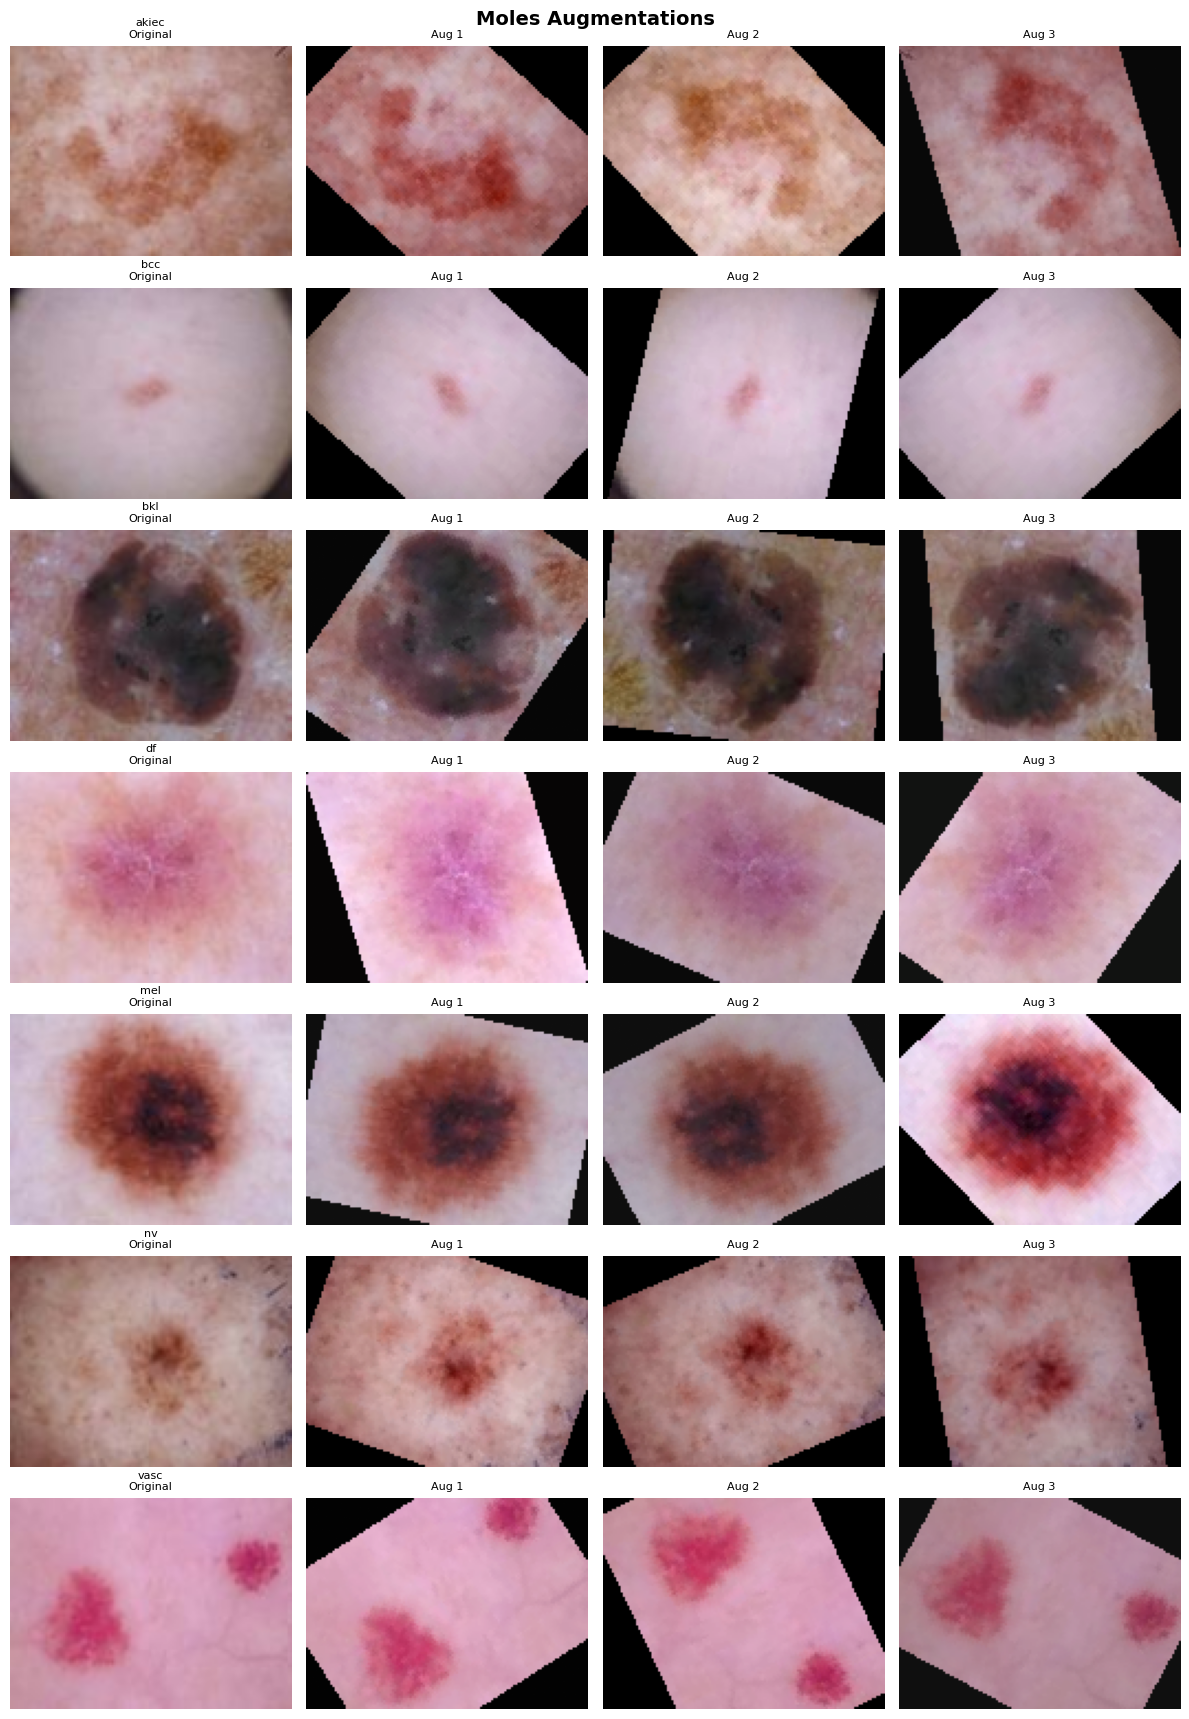

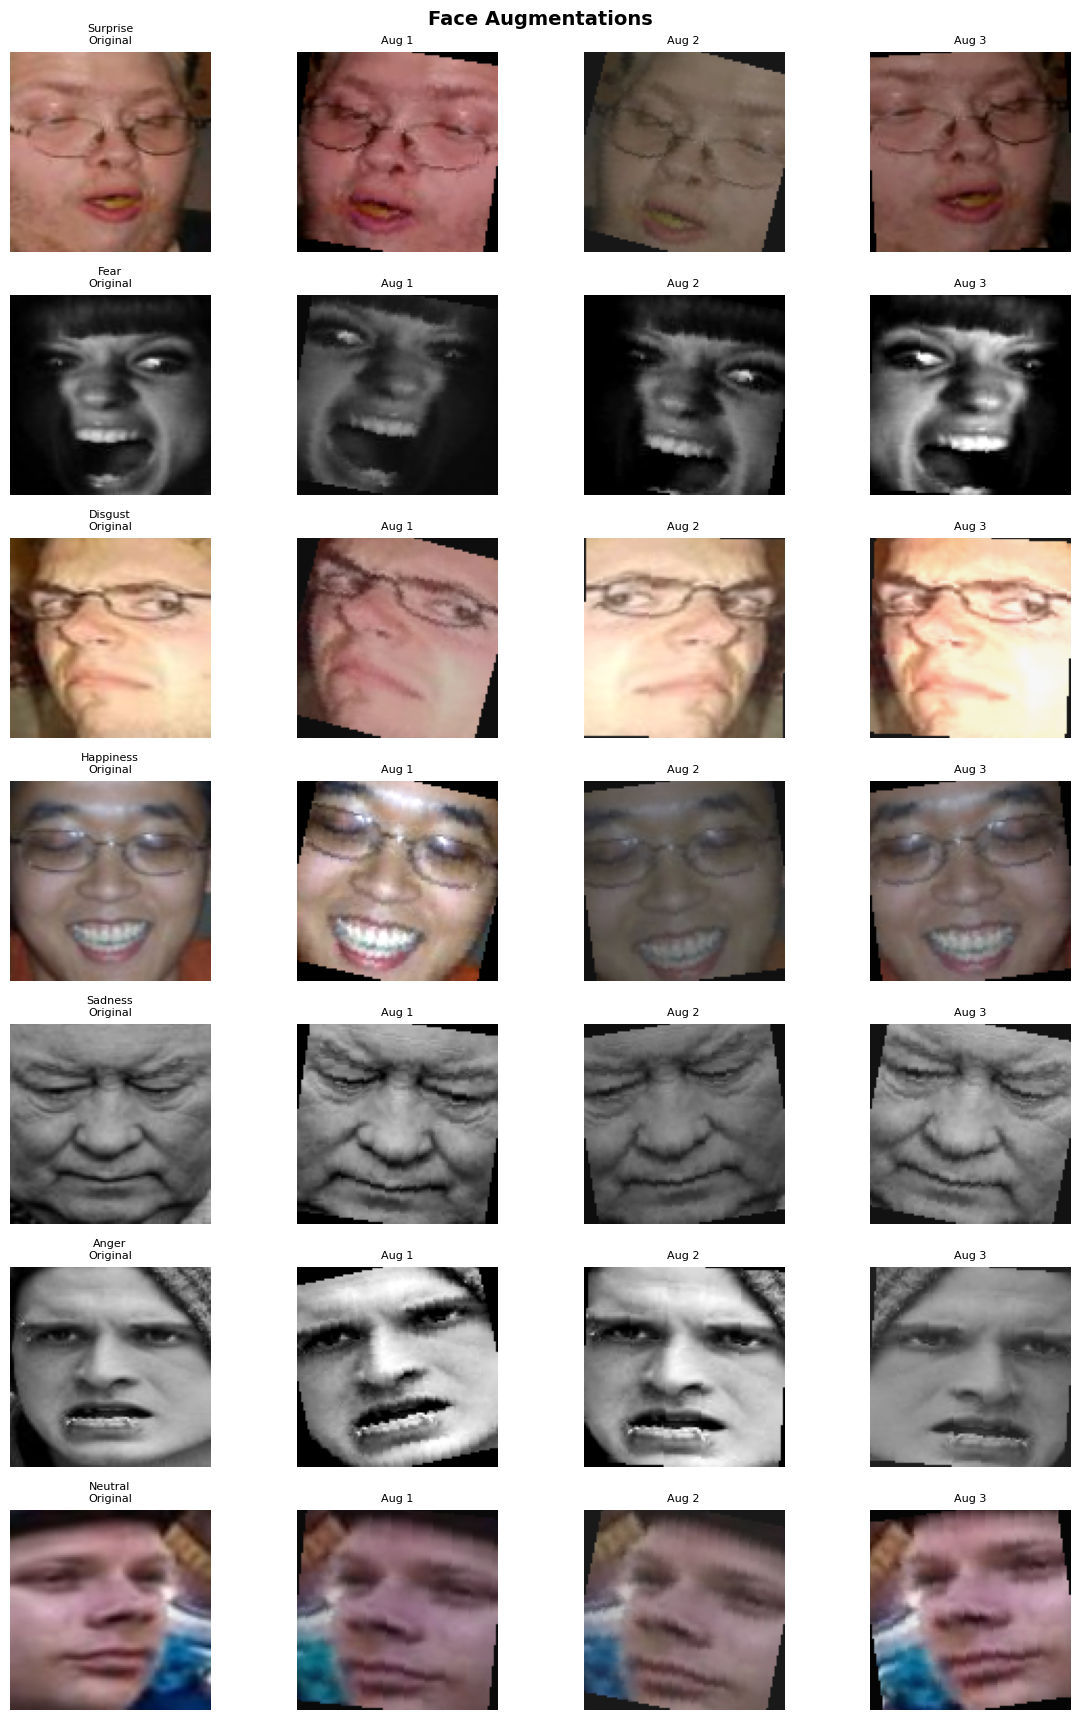

In [7]:
def denormalize(tensor, mean, std):
    t = tensor.clone()
    for c, m, s in zip(range(3), mean, std):
        t[c] = t[c] * s + m
    return t.clamp(0, 1).permute(1, 2, 0).numpy()

def viz_augmentations(ds_no_aug, ds_aug, class_names, mean, std, n_per_class=3, title=''):
    """Afiseaza cate n_per_class exemple augmentate per clasa."""
    # Grupam indecsii pe clasa
    class_indices = {c: [] for c in range(len(class_names))}
    for i, (_, lbl) in enumerate(ds_no_aug):
        class_indices[lbl].append(i)
        if all(len(v) >= 1 for v in class_indices.values()):
            break

    n_classes = len(class_names)
    fig, axes = plt.subplots(n_classes, n_per_class + 1, figsize=(3*(n_per_class+1), 2.5*n_classes))
    fig.suptitle(title, fontsize=14, fontweight='bold')

    for cls_idx in range(n_classes):
        if not class_indices[cls_idx]:
            continue
        sample_idx = class_indices[cls_idx][0]

        # Imaginea originala (fara aug)
        orig_img, _ = ds_no_aug[sample_idx]
        axes[cls_idx, 0].imshow(denormalize(orig_img, mean, std))
        axes[cls_idx, 0].set_title(f'{class_names[cls_idx]}\nOriginal', fontsize=8)
        axes[cls_idx, 0].axis('off')

        # Imagini augmentate
        for aug_i in range(n_per_class):
            aug_img, _ = ds_aug[sample_idx]
            axes[cls_idx, aug_i+1].imshow(denormalize(aug_img, mean, std))
            axes[cls_idx, aug_i+1].set_title(f'Aug {aug_i+1}', fontsize=8)
            axes[cls_idx, aug_i+1].axis('off')

    plt.tight_layout()
    plt.savefig(f'{BASE}/{title.lower().replace(" ","_")}_augmentations.png', bbox_inches='tight')
    plt.show()

# Dataset-uri cu si fara augmentare pentru vizualizare
moles_aug_ds_viz = MolesDataset(f'{BASE}/train.csv', f'{BASE}/train', moles_aug_tf)
moles_noaug_ds_viz = MolesDataset(f'{BASE}/train.csv', f'{BASE}/train', moles_val_tf)

face_aug_ds_viz = FacesDataset(f'{BASE}/splits/train.csv', face_aug_tf)
face_noaug_ds_viz = FacesDataset(f'{BASE}/splits/train.csv', face_val_tf)

viz_augmentations(moles_noaug_ds_viz, moles_aug_ds_viz, MOLES_CLASSES, MOLES_MEAN, MOLES_STD,
                  n_per_class=3, title='Moles Augmentations')
viz_augmentations(face_noaug_ds_viz, face_aug_ds_viz, FACE_CLASSES, FACE_MEAN, FACE_STD,
                  n_per_class=3, title='Face Augmentations')

## Utilitati comune: antrenare, evaluare, metrici

In [8]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        out = model(imgs)
        loss = criterion(out, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        correct += (out.argmax(1) == labels).sum().item()
        total += imgs.size(0)
    return total_loss / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        out = model(imgs)
        loss = criterion(out, labels)
        total_loss += loss.item() * imgs.size(0)
        preds = out.argmax(1)
        correct += (preds == labels).sum().item()
        total += imgs.size(0)
        all_preds.extend(preds.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())
    return total_loss / total, correct / total, all_preds, all_labels

def run_experiment(model, train_loader, val_loader, criterion, optimizer, scheduler=None,
                   num_epochs=30, device='cpu', run_name='exp', log_dir='runs'):
    writer = SummaryWriter(log_dir=f'{log_dir}/{run_name}')
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    best_val_acc = 0
    best_state = None

    for epoch in range(num_epochs):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        va_loss, va_acc, _, _ = evaluate(model, val_loader, criterion, device)

        if scheduler:
            scheduler.step()

        history['train_loss'].append(tr_loss)
        history['train_acc'].append(tr_acc)
        history['val_loss'].append(va_loss)
        history['val_acc'].append(va_acc)

        writer.add_scalar('Loss/train', tr_loss, epoch)
        writer.add_scalar('Loss/val', va_loss, epoch)
        writer.add_scalar('Acc/train', tr_acc, epoch)
        writer.add_scalar('Acc/val', va_acc, epoch)
        writer.add_scalar('LR', optimizer.param_groups[0]['lr'], epoch)

        if va_acc > best_val_acc:
            best_val_acc = va_acc
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

        if (epoch + 1) % 5 == 0:
            print(f'  Ep {epoch+1:3d} | train loss={tr_loss:.4f} acc={tr_acc:.3f} | val loss={va_loss:.4f} acc={va_acc:.3f}')

    writer.close()
    model.load_state_dict(best_state)
    return history

def plot_history(histories, labels, title='', save_path=None):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    fig.suptitle(title, fontsize=13)
    for h, lbl in zip(histories, labels):
        axes[0].plot(h['train_loss'], linestyle='--', label=f'{lbl} train')
        axes[0].plot(h['val_loss'], label=f'{lbl} val')
        axes[1].plot(h['train_acc'], linestyle='--', label=f'{lbl} train')
        axes[1].plot(h['val_acc'], label=f'{lbl} val')
    axes[0].set_title('Loss'); axes[0].set_xlabel('Epoca'); axes[0].legend(fontsize=7)
    axes[1].set_title('Accuracy'); axes[1].set_xlabel('Epoca'); axes[1].legend(fontsize=7)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, bbox_inches='tight')
    plt.show()

def compute_metrics(labels, preds, num_classes):
    """Calculeaza accuracy, F1-macro, F1-micro si matricea de confuzie cu numpy."""
    labels = np.array(labels)
    preds  = np.array(preds)
    acc = (labels == preds).mean()

    # Matrice de confuzie
    cm = np.zeros((num_classes, num_classes), dtype=int)
    for t, p in zip(labels, preds):
        cm[t, p] += 1

    # F1 per clasa -> macro si micro
    tp = np.diag(cm)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp
    denom_p = np.where(tp + fp > 0, tp + fp, 1)
    precision = np.where(tp + fp > 0, tp / denom_p, 0.0)
    denom_r = np.where(tp + fn > 0, tp + fn, 1)
    recall    = np.where(tp + fn > 0, tp / denom_r, 0.0)
    denom_f = np.where(precision + recall > 0, precision + recall, 1)
    f1_per    = np.where(precision + recall > 0,
                         2 * precision * recall / denom_f, 0.0)
    f1_macro = f1_per.mean()
    f1_micro = tp.sum() / (tp.sum() + 0.5 * (fp.sum() + fn.sum()) + 1e-9)

    return acc, f1_macro, f1_micro, cm, precision, recall, f1_per

def plot_confusion_matrix(cm, class_names, title=''):
    fig, ax = plt.subplots(figsize=(8, 6))
    im = ax.imshow(cm, interpolation='nearest', cmap='Blues')
    plt.colorbar(im, ax=ax)
    ax.set_xticks(range(len(class_names))); ax.set_xticklabels(class_names, rotation=45, ha='right')
    ax.set_yticks(range(len(class_names))); ax.set_yticklabels(class_names)
    thresh = cm.max() / 2.0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]), ha='center', va='center',
                    color='white' if cm[i, j] > thresh else 'black', fontsize=8)
    ax.set_title(f'Confusion Matrix - {title}')
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    plt.tight_layout()
    plt.savefig(f'{BASE}/cm_{title.lower().replace(" ","_")}.png', bbox_inches='tight')
    plt.show()

def report_metrics(model, loader, criterion, class_names, device, title=''):
    _, acc, preds, labels = evaluate(model, loader, criterion, device)
    acc, f1_macro, f1_micro, cm, prec, rec, f1_per = compute_metrics(labels, preds, len(class_names))
    print(f'\n=== {title} ===')
    print(f'Accuracy: {acc:.4f} | F1-macro: {f1_macro:.4f} | F1-micro: {f1_micro:.4f}')
    print(f'{"Clasa":<12} {"Precision":>10} {"Recall":>8} {"F1":>8}')
    for i, cls in enumerate(class_names):
        print(f'  {cls:<10} {prec[i]:>10.3f} {rec[i]:>8.3f} {f1_per[i]:>8.3f}')
    plot_confusion_matrix(cm, class_names, title)
    return acc, f1_macro, f1_micro


def get_class_weights(dataset, num_classes, device):
    counts = np.bincount([lbl for _, lbl in dataset], minlength=num_classes).astype(float)
    weights = counts.sum() / (num_classes * counts)
    return torch.tensor(weights, dtype=torch.float).to(device)

def make_weighted_sampler(dataset, num_classes):
    labels = np.array([lbl for _, lbl in dataset])
    counts = np.bincount(labels, minlength=num_classes).astype(float)
    class_w = 1.0 / counts
    sample_w = class_w[labels]
    return WeightedRandomSampler(torch.from_numpy(sample_w).double(),
                                 num_samples=len(sample_w), replacement=True)
print('Utilities defined.')

Utilities defined.


## 3.2 Arhitectura MLP

In [9]:
class MLP(nn.Module):
    """
    MLP pentru clasificare imagini 96x128 (moles) sau 96x96 (faces).
    Arhitectura: Flatten -> 4 straturi Linear cu BatchNorm1d + ReLU + Dropout optional.
    Motivare: straturi progresiv mai mici (2048->512->128->num_classes) permit
    extragerea de features ierarhice; BN1d stabilizeaza antrenarea; dropout reduce overfitting.
    """
    def __init__(self, input_size, num_classes, use_dropout=True, dropout_p=0.4):
        super().__init__()
        layers = [
            nn.Flatten(),
            nn.Linear(input_size, 2048),
            nn.BatchNorm1d(2048),
            nn.ReLU(inplace=True),
        ]
        if use_dropout: layers.append(nn.Dropout(dropout_p))
        layers += [
            nn.Linear(2048, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
        ]
        if use_dropout: layers.append(nn.Dropout(dropout_p))
        layers += [
            nn.Linear(512, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
        ]
        if use_dropout: layers.append(nn.Dropout(dropout_p / 2))
        layers.append(nn.Linear(128, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

# Dimensiuni de intrare: 3 * H * W
MOLES_INPUT = 3 * 96 * 128   # = 36864
FACE_INPUT  = 3 * 96 * 96    # = 27648
N_EPOCHS_MLP = 40
BS = 64

print(f'MLP moles input: {MOLES_INPUT}, face input: {FACE_INPUT}')

MLP moles input: 36864, face input: 27648


In [10]:
# --- MLP MOLES cu Dropout ---
print('=== MLP Moles (cu dropout) ===')
moles_train_loader = DataLoader(moles_train_ds, batch_size=BS, shuffle=True, num_workers=2, drop_last=True)
moles_val_loader   = DataLoader(moles_val_ds,   batch_size=BS, shuffle=False, num_workers=2)

mlp_moles_drop = MLP(MOLES_INPUT, len(MOLES_CLASSES), use_dropout=True).to(device)
opt_moles_drop = optim.Adam(mlp_moles_drop.parameters(), lr=1e-3, weight_decay=1e-4)
sch_moles_drop = optim.lr_scheduler.CosineAnnealingLR(opt_moles_drop, T_max=N_EPOCHS_MLP)
crit_moles = nn.CrossEntropyLoss()

hist_mlp_moles_drop = run_experiment(
    mlp_moles_drop, moles_train_loader, moles_val_loader,
    crit_moles, opt_moles_drop, sch_moles_drop,
    num_epochs=N_EPOCHS_MLP, device=device,
    run_name='mlp_moles_dropout', log_dir=f'{BASE}/runs'
)

=== MLP Moles (cu dropout) ===
  Ep   5 | train loss=0.7895 acc=0.707 | val loss=0.8086 acc=0.722
  Ep  10 | train loss=0.7349 acc=0.732 | val loss=0.7888 acc=0.725
  Ep  15 | train loss=0.7064 acc=0.739 | val loss=0.7806 acc=0.715
  Ep  20 | train loss=0.6580 acc=0.751 | val loss=0.8202 acc=0.718
  Ep  25 | train loss=0.6024 acc=0.773 | val loss=0.7332 acc=0.739
  Ep  30 | train loss=0.5267 acc=0.805 | val loss=0.7204 acc=0.745
  Ep  35 | train loss=0.4137 acc=0.852 | val loss=0.7268 acc=0.752
  Ep  40 | train loss=0.3525 acc=0.876 | val loss=0.7299 acc=0.755


=== MLP Moles (fara dropout) ===
  Ep   5 | train loss=0.7479 acc=0.724 | val loss=0.7863 acc=0.717
  Ep  10 | train loss=0.6465 acc=0.758 | val loss=0.8311 acc=0.707
  Ep  15 | train loss=0.5501 acc=0.795 | val loss=0.7814 acc=0.735
  Ep  20 | train loss=0.4453 acc=0.838 | val loss=0.8495 acc=0.707
  Ep  25 | train loss=0.3193 acc=0.880 | val loss=0.8483 acc=0.721
  Ep  30 | train loss=0.1714 acc=0.944 | val loss=0.9529 acc=0.716
  Ep  35 | train loss=0.0713 acc=0.984 | val loss=1.0046 acc=0.741
  Ep  40 | train loss=0.0446 acc=0.993 | val loss=1.0284 acc=0.743


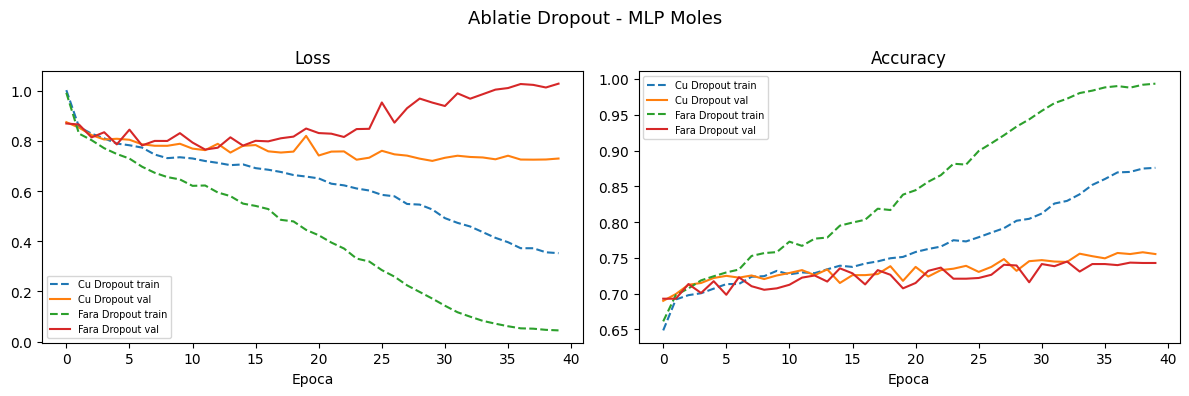

In [11]:
# --- MLP MOLES fara Dropout --------------------------------------------------
print('=== MLP Moles (fara dropout) ===')
mlp_moles_nodrop = MLP(MOLES_INPUT, len(MOLES_CLASSES), use_dropout=False).to(device)
opt_moles_nodrop = optim.Adam(mlp_moles_nodrop.parameters(), lr=1e-3, weight_decay=1e-4)
sch_moles_nodrop = optim.lr_scheduler.CosineAnnealingLR(opt_moles_nodrop, T_max=N_EPOCHS_MLP)

hist_mlp_moles_nodrop = run_experiment(
    mlp_moles_nodrop, moles_train_loader, moles_val_loader,
    crit_moles, opt_moles_nodrop, sch_moles_nodrop,
    num_epochs=N_EPOCHS_MLP, device=device,
    run_name='mlp_moles_nodropout', log_dir=f'{BASE}/runs'
)

plot_history([hist_mlp_moles_drop, hist_mlp_moles_nodrop],
             ['Cu Dropout', 'Fara Dropout'],
             title='Ablatie Dropout - MLP Moles',
             save_path=f'{BASE}/ablatie_dropout_moles.png')

In [12]:
# --- MLP FACES cu Dropout ---
print('=== MLP Faces (cu dropout) ===')
face_train_loader = DataLoader(face_train_ds, batch_size=BS, shuffle=True, num_workers=2, drop_last=True)
face_val_loader   = DataLoader(face_val_ds,   batch_size=BS, shuffle=False, num_workers=2)

mlp_face_drop = MLP(FACE_INPUT, len(FACE_CLASSES), use_dropout=True).to(device)
opt_face_drop = optim.Adam(mlp_face_drop.parameters(), lr=1e-3, weight_decay=1e-4)
sch_face_drop = optim.lr_scheduler.CosineAnnealingLR(opt_face_drop, T_max=N_EPOCHS_MLP)
crit_face = nn.CrossEntropyLoss()

hist_mlp_face_drop = run_experiment(
    mlp_face_drop, face_train_loader, face_val_loader,
    crit_face, opt_face_drop, sch_face_drop,
    num_epochs=N_EPOCHS_MLP, device=device,
    run_name='mlp_face_dropout', log_dir=f'{BASE}/runs'
)

=== MLP Faces (cu dropout) ===
  Ep   5 | train loss=1.0413 acc=0.628 | val loss=1.0499 acc=0.628
  Ep  10 | train loss=0.9738 acc=0.650 | val loss=1.0294 acc=0.638
  Ep  15 | train loss=0.9105 acc=0.672 | val loss=1.0511 acc=0.623
  Ep  20 | train loss=0.8441 acc=0.697 | val loss=0.9448 acc=0.677
  Ep  25 | train loss=0.7442 acc=0.735 | val loss=0.9534 acc=0.676
  Ep  30 | train loss=0.6054 acc=0.787 | val loss=0.9637 acc=0.685
  Ep  35 | train loss=0.4667 acc=0.840 | val loss=0.9565 acc=0.695
  Ep  40 | train loss=0.3826 acc=0.872 | val loss=0.9543 acc=0.703


=== MLP Faces (fara dropout) ===
  Ep   5 | train loss=0.9163 acc=0.673 | val loss=1.1860 acc=0.579
  Ep  10 | train loss=0.7793 acc=0.720 | val loss=1.0196 acc=0.658
  Ep  15 | train loss=0.6094 acc=0.780 | val loss=1.1123 acc=0.629
  Ep  20 | train loss=0.4520 acc=0.836 | val loss=1.1546 acc=0.654
  Ep  25 | train loss=0.2589 acc=0.913 | val loss=1.3013 acc=0.645
  Ep  30 | train loss=0.1313 acc=0.961 | val loss=1.4365 acc=0.667
  Ep  35 | train loss=0.0606 acc=0.985 | val loss=1.4951 acc=0.671
  Ep  40 | train loss=0.0354 acc=0.993 | val loss=1.4860 acc=0.673


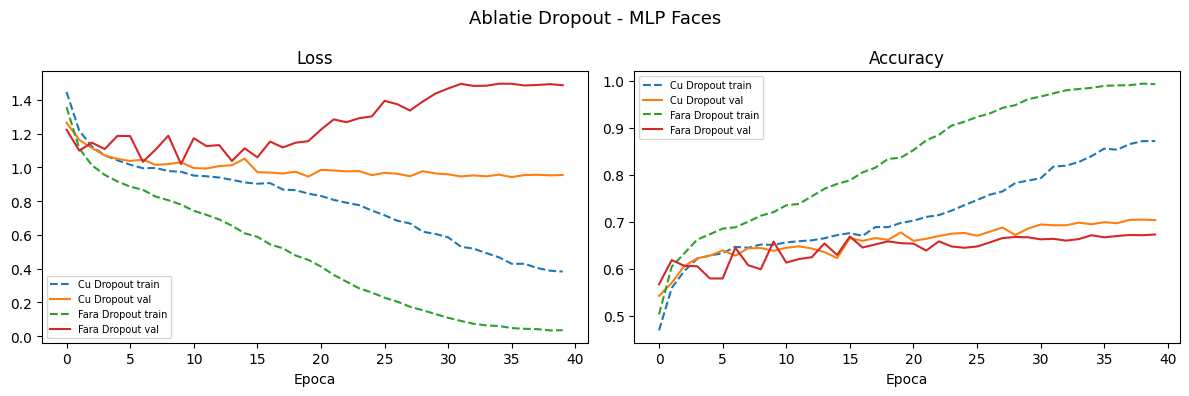


=== MLP Moles cu Dropout ===
Accuracy: 0.7579 | F1-macro: 0.4923 | F1-micro: 0.7579
Clasa         Precision   Recall       F1
  akiec           0.500    0.400    0.444
  bcc             0.573    0.534    0.553
  bkl             0.513    0.459    0.484
  df              0.222    0.087    0.125
  mel             0.503    0.342    0.408
  nv              0.843    0.928    0.883
  vasc            0.636    0.483    0.549


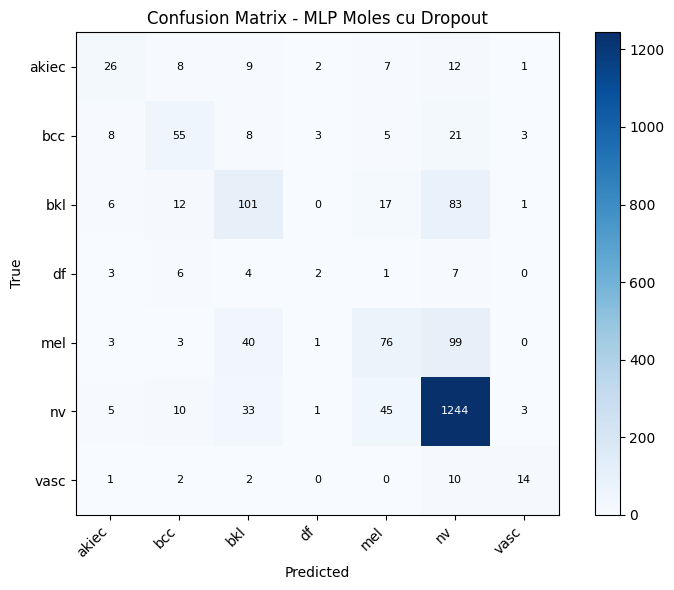


=== MLP Faces cu Dropout ===
Accuracy: 0.7044 | F1-macro: 0.5765 | F1-micro: 0.7044
Clasa         Precision   Recall       F1
  Surprise        0.678    0.731    0.703
  Fear            0.529    0.214    0.305
  Disgust         0.393    0.327    0.357
  Happiness       0.848    0.852    0.850
  Sadness         0.629    0.593    0.610
  Anger           0.574    0.514    0.543
  Neutral         0.626    0.714    0.667


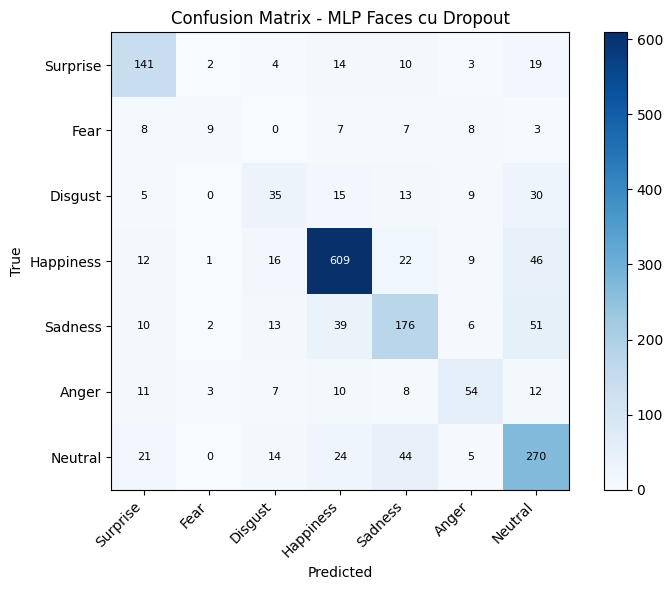

(0.7044093630919979, 0.576527270933474, 0.7044093630916144)

In [13]:
# --- MLP FACES fara Dropout --------------------------------------------------
print('=== MLP Faces (fara dropout) ===')
mlp_face_nodrop = MLP(FACE_INPUT, len(FACE_CLASSES), use_dropout=False).to(device)
opt_face_nodrop = optim.Adam(mlp_face_nodrop.parameters(), lr=1e-3, weight_decay=1e-4)
sch_face_nodrop = optim.lr_scheduler.CosineAnnealingLR(opt_face_nodrop, T_max=N_EPOCHS_MLP)

hist_mlp_face_nodrop = run_experiment(
    mlp_face_nodrop, face_train_loader, face_val_loader,
    crit_face, opt_face_nodrop, sch_face_nodrop,
    num_epochs=N_EPOCHS_MLP, device=device,
    run_name='mlp_face_nodropout', log_dir=f'{BASE}/runs'
)

plot_history([hist_mlp_face_drop, hist_mlp_face_nodrop],
             ['Cu Dropout', 'Fara Dropout'],
             title='Ablatie Dropout - MLP Faces',
             save_path=f'{BASE}/ablatie_dropout_faces.png')

# Metrici finale MLP
report_metrics(mlp_moles_drop, moles_val_loader, crit_moles, MOLES_CLASSES, device, 'MLP Moles cu Dropout')
report_metrics(mlp_face_drop,  face_val_loader,  crit_face,  FACE_CLASSES,  device, 'MLP Faces cu Dropout')

## 3.3 Arhitectura CNN

In [14]:
class CNN(nn.Module):
    """
    CNN comun celor doua seturi de date.
    Arhitectura: 4 blocuri Conv -> BN -> ReLU -> MaxPool + GlobalAvgPool + 2 straturi FC.
    Motivare:
      - Primul conv: kernel 5x5 pentru moles (features de scara mai mare), 3x3 pentru faces
      - AdaptiveAvgPool2d(1): agnostic la rezolutie, elimina nevoie de FC mare
      - BatchNorm2d: stabilizare, LR mai mare posibil, efect de regularizare
      - Dropout doar pe FC, nu intre Conv si BN
    """
    def __init__(self, num_classes, first_kernel=3, use_bn=True, dropout_p=0.5):
        super().__init__()
        self.use_bn = use_bn

        def conv_block(in_c, out_c, k=3, use_bn=True):
            layers = [nn.Conv2d(in_c, out_c, k, padding=k//2, bias=not use_bn)]
            if use_bn: layers.append(nn.BatchNorm2d(out_c))
            layers += [nn.ReLU(inplace=True), nn.MaxPool2d(2)]
            return layers

        self.features = nn.Sequential(
            *conv_block(3, 32,  k=first_kernel, use_bn=use_bn),  # Block 1
            *conv_block(32, 64, k=3, use_bn=use_bn),             # Block 2
            *conv_block(64, 128, k=3, use_bn=use_bn),            # Block 3
            *conv_block(128, 256, k=3, use_bn=use_bn),           # Block 4
            nn.AdaptiveAvgPool2d(1),                             # Global Avg Pool
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout_p),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

print('CNN defined.')

CNN defined.


In [15]:
# --- Configuratii augmentare pentru ablatie CNN ----------------------------
def make_moles_tf(geom=False, color=False):
    base = [transforms.Resize((96, 128))]
    if geom:
        base += [transforms.RandomHorizontalFlip(0.5),
                 transforms.RandomVerticalFlip(0.5),
                 transforms.RandomRotation(180)]
    if color:
        base += [transforms.ColorJitter(0.15, 0.15, 0.1, 0.05)]
    base += [transforms.ToTensor(), transforms.Normalize(MOLES_MEAN, MOLES_STD)]
    return transforms.Compose(base)

def make_face_tf(geom=False, color=False):
    base = [transforms.Resize((108, 108))]
    if geom:
        base += [transforms.RandomCrop(96),
                 transforms.RandomHorizontalFlip(0.5),
                 transforms.RandomRotation(15)]
    else:
        base += [transforms.Resize((96, 96))]
    if color:
        base += [transforms.ColorJitter(0.3, 0.3, 0.2, 0.05)]
    base += [transforms.ToTensor(), transforms.Normalize(FACE_MEAN, FACE_STD)]
    return transforms.Compose(base)

AUG_CONFIGS = [
    ('Fara augmentari', False, False),
    ('Geometrice',      True,  False),
    ('Culoare',         False, True),
    ('Toate',           True,  True),
]
N_EPOCHS_CNN = 40

print('Aug configs ready.')

Aug configs ready.



=== CNN Moles - Fara augmentari ===


  Ep   5 | train loss=0.7748 acc=0.711 | val loss=0.7607 acc=0.715
  Ep  10 | train loss=0.7247 acc=0.720 | val loss=0.7082 acc=0.736
  Ep  15 | train loss=0.6916 acc=0.741 | val loss=0.6870 acc=0.747
  Ep  20 | train loss=0.6484 acc=0.754 | val loss=0.6770 acc=0.736
  Ep  25 | train loss=0.6144 acc=0.771 | val loss=0.6251 acc=0.767
  Ep  30 | train loss=0.5784 acc=0.782 | val loss=0.6127 acc=0.771
  Ep  35 | train loss=0.5436 acc=0.798 | val loss=0.5988 acc=0.780
  Ep  40 | train loss=0.5291 acc=0.802 | val loss=0.5917 acc=0.779

=== CNN Moles - Geometrice ===
  Ep   5 | train loss=0.8116 acc=0.695 | val loss=0.8239 acc=0.705
  Ep  10 | train loss=0.7484 acc=0.712 | val loss=0.7378 acc=0.733
  Ep  15 | train loss=0.7076 acc=0.729 | val loss=0.7136 acc=0.734
  Ep  20 | train loss=0.6864 acc=0.737 | val loss=0.6853 acc=0.745
  Ep  25 | train loss=0.6552 acc=0.754 | val loss=0.6840 acc=0.748
  Ep  30 | train loss=0.6359 acc=0.761 | val loss=0.6793 acc=0.745
  Ep  35 | train loss=0.6150 a

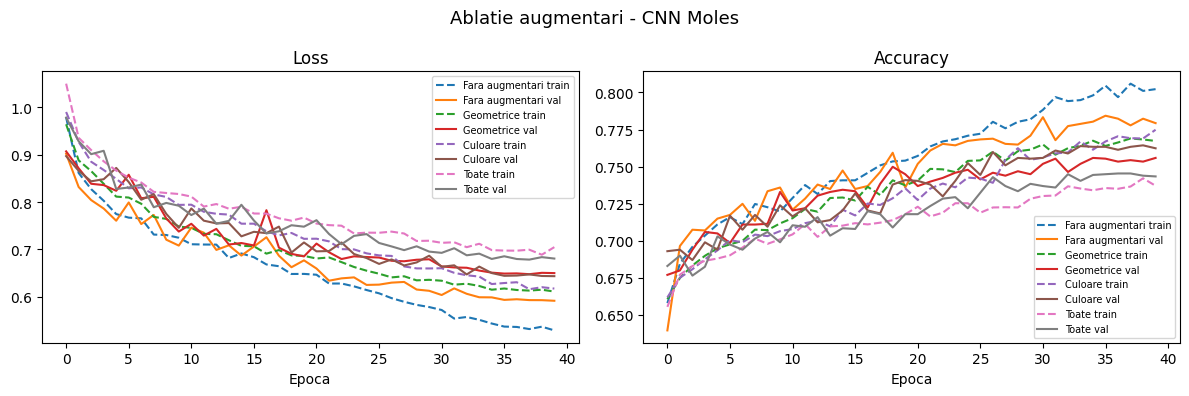

In [16]:
# --- CNN MOLES: ablatie augmentari -------------------------------------------
cnn_moles_aug_histories = []
cnn_moles_aug_models = []

for name, geom, color in AUG_CONFIGS:
    print(f'\n=== CNN Moles - {name} ===')
    tf = make_moles_tf(geom, color)
    ds = MolesDataset(f'{BASE}/train.csv', f'{BASE}/train', tf)
    loader = DataLoader(ds, batch_size=BS, shuffle=True, num_workers=2, drop_last=True)

    model = CNN(len(MOLES_CLASSES), first_kernel=5, use_bn=True).to(device)
    opt = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    sch = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=N_EPOCHS_CNN)

    h = run_experiment(model, loader, moles_val_loader, crit_moles, opt, sch,
                       num_epochs=N_EPOCHS_CNN, device=device,
                       run_name=f'cnn_moles_aug_{name.lower().replace(" ","_")}',
                       log_dir=f'{BASE}/runs')
    cnn_moles_aug_histories.append(h)
    cnn_moles_aug_models.append(model)

plot_history(cnn_moles_aug_histories, [c[0] for c in AUG_CONFIGS],
             title='Ablatie augmentari - CNN Moles',
             save_path=f'{BASE}/ablatie_aug_moles.png')


=== CNN Faces - Fara augmentari ===


  Ep   5 | train loss=1.2632 acc=0.540 | val loss=1.4140 acc=0.468
  Ep  10 | train loss=0.9158 acc=0.679 | val loss=0.9990 acc=0.649
  Ep  15 | train loss=0.6881 acc=0.760 | val loss=0.9364 acc=0.673
  Ep  20 | train loss=0.4805 acc=0.841 | val loss=1.2681 acc=0.606
  Ep  25 | train loss=0.3103 acc=0.899 | val loss=0.9782 acc=0.709
  Ep  30 | train loss=0.2011 acc=0.940 | val loss=1.0960 acc=0.688
  Ep  35 | train loss=0.1537 acc=0.958 | val loss=0.9774 acc=0.714
  Ep  40 | train loss=0.1365 acc=0.969 | val loss=0.9611 acc=0.721

=== CNN Faces - Geometrice ===
  Ep   5 | train loss=1.4965 acc=0.432 | val loss=1.4844 acc=0.451
  Ep  10 | train loss=1.2221 acc=0.558 | val loss=1.3259 acc=0.501
  Ep  15 | train loss=1.0274 acc=0.641 | val loss=1.1763 acc=0.559
  Ep  20 | train loss=0.9003 acc=0.686 | val loss=1.0528 acc=0.612
  Ep  25 | train loss=0.8187 acc=0.719 | val loss=1.0884 acc=0.603
  Ep  30 | train loss=0.7648 acc=0.741 | val loss=1.0142 acc=0.628
  Ep  35 | train loss=0.7217 a

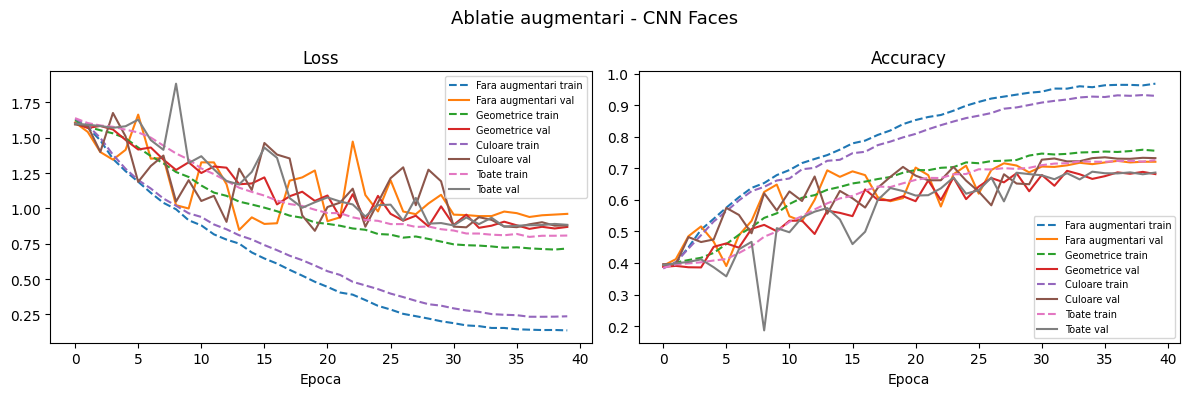

In [17]:
# --- CNN FACES: ablatie augmentari -------------------------------------------
cnn_face_aug_histories = []
cnn_face_aug_models = []

for name, geom, color in AUG_CONFIGS:
    print(f'\n=== CNN Faces - {name} ===')
    tf = make_face_tf(geom, color)
    ds = FacesDataset(f'{BASE}/splits/train.csv', tf)
    loader = DataLoader(ds, batch_size=BS, shuffle=True, num_workers=2, drop_last=True)

    model = CNN(len(FACE_CLASSES), first_kernel=3, use_bn=True).to(device)
    opt = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    sch = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=N_EPOCHS_CNN)

    h = run_experiment(model, loader, face_val_loader, crit_face, opt, sch,
                       num_epochs=N_EPOCHS_CNN, device=device,
                       run_name=f'cnn_face_aug_{name.lower().replace(" ","_")}',
                       log_dir=f'{BASE}/runs')
    cnn_face_aug_histories.append(h)
    cnn_face_aug_models.append(model)

plot_history(cnn_face_aug_histories, [c[0] for c in AUG_CONFIGS],
             title='Ablatie augmentari - CNN Faces',
             save_path=f'{BASE}/ablatie_aug_faces.png')

=== CNN Moles - cu BN vs fara BN ===
  Ep   5 | train loss=0.8684 acc=0.686 | val loss=0.8412 acc=0.693
  Ep  10 | train loss=0.8171 acc=0.699 | val loss=0.7778 acc=0.716
  Ep  15 | train loss=0.7763 acc=0.713 | val loss=0.7611 acc=0.702
  Ep  20 | train loss=0.7572 acc=0.719 | val loss=0.7396 acc=0.727
  Ep  25 | train loss=0.7346 acc=0.727 | val loss=0.6992 acc=0.743
  Ep  30 | train loss=0.7152 acc=0.737 | val loss=0.6984 acc=0.747
  Ep  35 | train loss=0.6969 acc=0.744 | val loss=0.6827 acc=0.756
  Ep  40 | train loss=0.6882 acc=0.742 | val loss=0.6771 acc=0.756
  Ep   5 | train loss=0.9745 acc=0.670 | val loss=0.9227 acc=0.669
  Ep  10 | train loss=0.8806 acc=0.680 | val loss=0.8957 acc=0.677
  Ep  15 | train loss=0.8325 acc=0.696 | val loss=0.8780 acc=0.689
  Ep  20 | train loss=0.8171 acc=0.701 | val loss=0.7825 acc=0.707
  Ep  25 | train loss=0.7982 acc=0.715 | val loss=0.7794 acc=0.715
  Ep  30 | train loss=0.7713 acc=0.715 | val loss=0.7560 acc=0.720
  Ep  35 | train loss=0.7

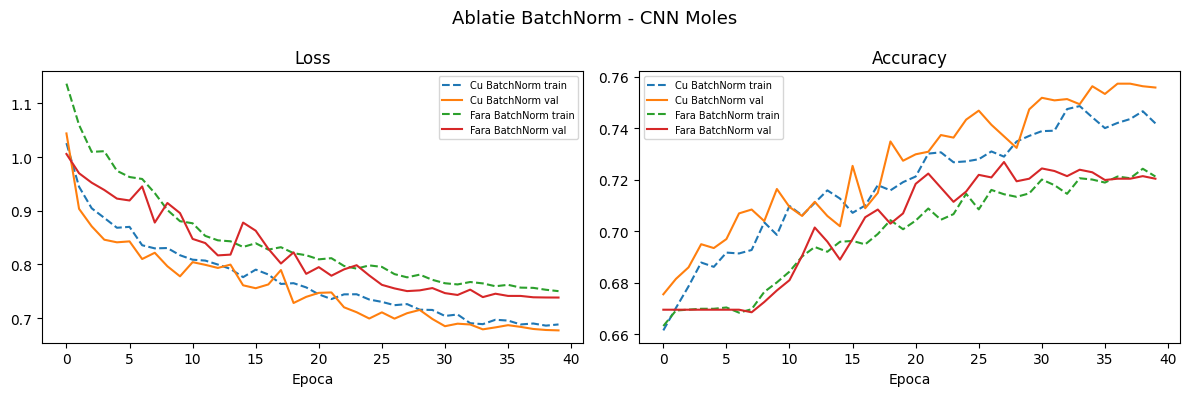

In [18]:
# --- CNN: ablatie BatchNorm (cu toate augmentarile) --------------------------
print('=== CNN Moles - cu BN vs fara BN ===')
moles_aug_loader = DataLoader(
    MolesDataset(f'{BASE}/train.csv', f'{BASE}/train', make_moles_tf(True, True)),
    batch_size=BS, shuffle=True, num_workers=2, drop_last=True)

cnn_moles_bn = CNN(len(MOLES_CLASSES), first_kernel=5, use_bn=True).to(device)
opt_bn = optim.Adam(cnn_moles_bn.parameters(), lr=1e-3, weight_decay=1e-4)
hist_cnn_moles_bn = run_experiment(cnn_moles_bn, moles_aug_loader, moles_val_loader,
    crit_moles, opt_bn, optim.lr_scheduler.CosineAnnealingLR(opt_bn, T_max=N_EPOCHS_CNN),
    num_epochs=N_EPOCHS_CNN, device=device,
    run_name='cnn_moles_bn', log_dir=f'{BASE}/runs')

cnn_moles_nobn = CNN(len(MOLES_CLASSES), first_kernel=5, use_bn=False).to(device)
opt_nobn = optim.Adam(cnn_moles_nobn.parameters(), lr=1e-3, weight_decay=1e-4)
hist_cnn_moles_nobn = run_experiment(cnn_moles_nobn, moles_aug_loader, moles_val_loader,
    crit_moles, opt_nobn, optim.lr_scheduler.CosineAnnealingLR(opt_nobn, T_max=N_EPOCHS_CNN),
    num_epochs=N_EPOCHS_CNN, device=device,
    run_name='cnn_moles_nobn', log_dir=f'{BASE}/runs')

plot_history([hist_cnn_moles_bn, hist_cnn_moles_nobn], ['Cu BatchNorm', 'Fara BatchNorm'],
             title='Ablatie BatchNorm - CNN Moles',
             save_path=f'{BASE}/ablatie_bn_moles.png')

=== CNN Faces - cu BN vs fara BN ===
  Ep   5 | train loss=1.5622 acc=0.411 | val loss=1.6226 acc=0.409
  Ep  10 | train loss=1.3427 acc=0.504 | val loss=1.3912 acc=0.493
  Ep  15 | train loss=1.1131 acc=0.607 | val loss=1.4093 acc=0.483
  Ep  20 | train loss=0.9869 acc=0.654 | val loss=1.1264 acc=0.586
  Ep  25 | train loss=0.8980 acc=0.693 | val loss=1.1412 acc=0.576
  Ep  30 | train loss=0.8433 acc=0.712 | val loss=0.8918 acc=0.690
  Ep  35 | train loss=0.8017 acc=0.729 | val loss=0.8922 acc=0.687
  Ep  40 | train loss=0.7868 acc=0.732 | val loss=0.8780 acc=0.692
  Ep   5 | train loss=1.5838 acc=0.402 | val loss=1.6173 acc=0.385
  Ep  10 | train loss=1.4888 acc=0.435 | val loss=1.4720 acc=0.436
  Ep  15 | train loss=1.3342 acc=0.504 | val loss=1.3624 acc=0.468
  Ep  20 | train loss=1.2094 acc=0.558 | val loss=1.2384 acc=0.527
  Ep  25 | train loss=1.1017 acc=0.603 | val loss=1.1783 acc=0.572
  Ep  30 | train loss=1.0306 acc=0.633 | val loss=1.2068 acc=0.568
  Ep  35 | train loss=1.0

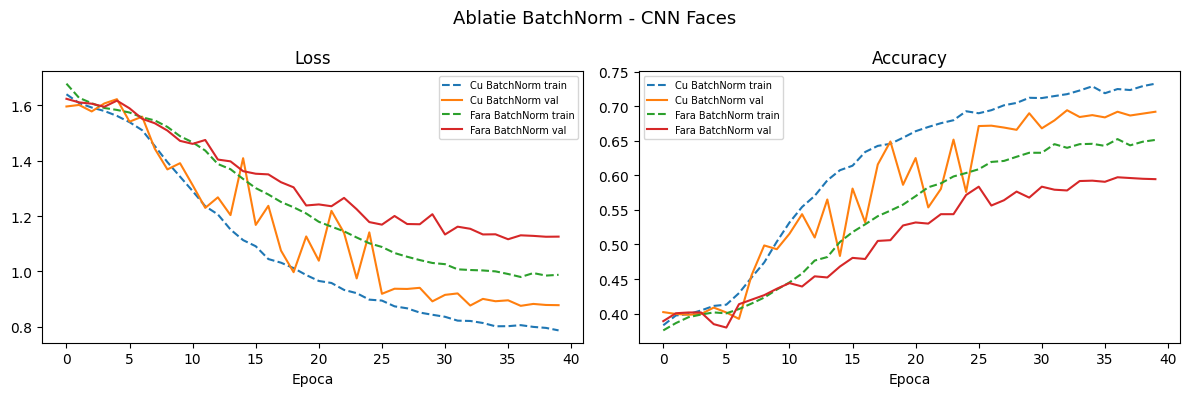


=== CNN Moles BN+Aug ===
Accuracy: 0.7574 | F1-macro: 0.4478 | F1-micro: 0.7574
Clasa         Precision   Recall       F1
  akiec           0.395    0.262    0.315
  bcc             0.592    0.408    0.483
  bkl             0.513    0.455    0.482
  df              0.000    0.000    0.000
  mel             0.513    0.351    0.417
  nv              0.831    0.945    0.884
  vasc            0.722    0.448    0.553


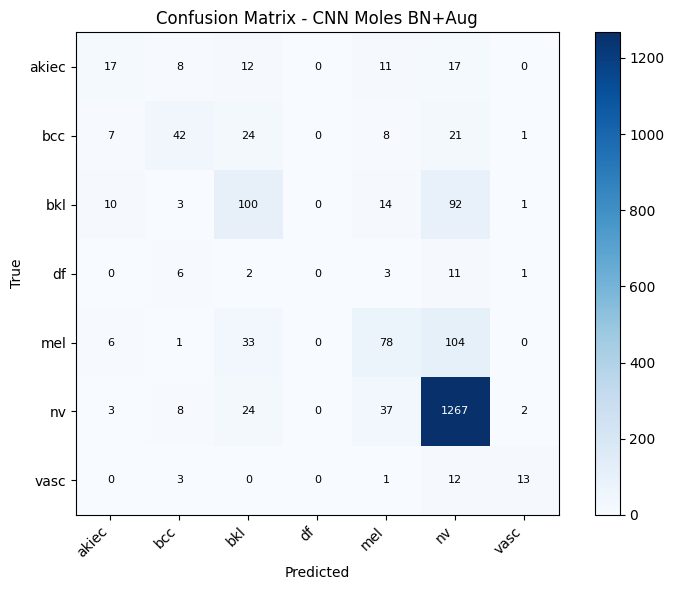


=== CNN Faces BN+Aug ===
Accuracy: 0.6941 | F1-macro: 0.4813 | F1-micro: 0.6941
Clasa         Precision   Recall       F1
  Surprise        0.772    0.788    0.779
  Fear            0.000    0.000    0.000
  Disgust         0.000    0.000    0.000
  Happiness       0.849    0.843    0.846
  Sadness         0.525    0.714    0.605
  Anger           0.399    0.600    0.479
  Neutral         0.671    0.648    0.659


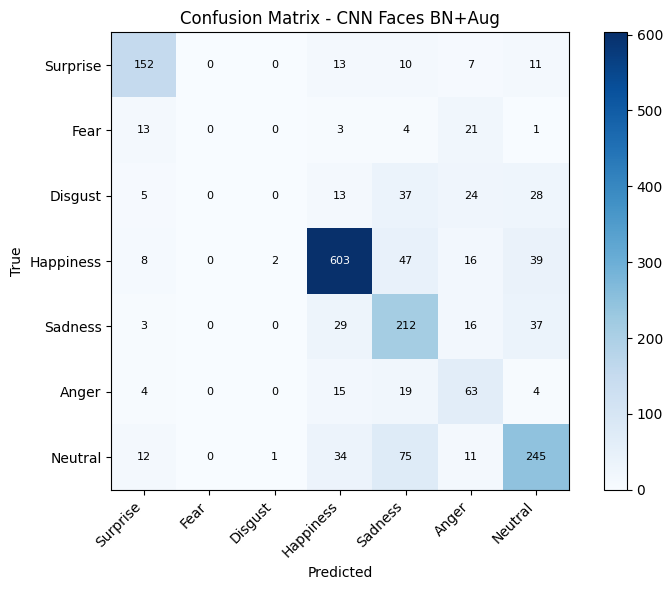

(0.6940664126292869, 0.48131845647210053, 0.6940664126289091)

In [19]:
print('=== CNN Faces - cu BN vs fara BN ===')
face_aug_loader = DataLoader(
    FacesDataset(f'{BASE}/splits/train.csv', make_face_tf(True, True)),
    batch_size=BS, shuffle=True, num_workers=2, drop_last=True)

cnn_face_bn = CNN(len(FACE_CLASSES), first_kernel=3, use_bn=True).to(device)
opt_fbn = optim.Adam(cnn_face_bn.parameters(), lr=1e-3, weight_decay=1e-4)
hist_cnn_face_bn = run_experiment(cnn_face_bn, face_aug_loader, face_val_loader,
    crit_face, opt_fbn, optim.lr_scheduler.CosineAnnealingLR(opt_fbn, T_max=N_EPOCHS_CNN),
    num_epochs=N_EPOCHS_CNN, device=device,
    run_name='cnn_face_bn', log_dir=f'{BASE}/runs')

cnn_face_nobn = CNN(len(FACE_CLASSES), first_kernel=3, use_bn=False).to(device)
opt_fnobn = optim.Adam(cnn_face_nobn.parameters(), lr=1e-3, weight_decay=1e-4)
hist_cnn_face_nobn = run_experiment(cnn_face_nobn, face_aug_loader, face_val_loader,
    crit_face, opt_fnobn, optim.lr_scheduler.CosineAnnealingLR(opt_fnobn, T_max=N_EPOCHS_CNN),
    num_epochs=N_EPOCHS_CNN, device=device,
    run_name='cnn_face_nobn', log_dir=f'{BASE}/runs')

plot_history([hist_cnn_face_bn, hist_cnn_face_nobn], ['Cu BatchNorm', 'Fara BatchNorm'],
             title='Ablatie BatchNorm - CNN Faces',
             save_path=f'{BASE}/ablatie_bn_faces.png')

# Metrici finale CNN (cel mai bun: cu BN + toate augmentarile)
report_metrics(cnn_moles_bn, moles_val_loader, crit_moles, MOLES_CLASSES, device, 'CNN Moles BN+Aug')
report_metrics(cnn_face_bn,  face_val_loader,  crit_face,  FACE_CLASSES,  device, 'CNN Faces BN+Aug')

## 3.4 Fine-tuning ResNet-18

In [20]:
# ResNet-18 fine-tuning setup
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

def make_resnet_tf(augment=True, is_moles=True):
    base = [transforms.Resize((224, 224))]
    if augment:
        if is_moles:
            base += [
                transforms.RandomHorizontalFlip(0.5),
                transforms.RandomVerticalFlip(0.5),
                transforms.RandomRotation(180),
                transforms.ColorJitter(0.2, 0.2, 0.15, 0.05),
            ]
        else:
            base += [
                transforms.RandomHorizontalFlip(0.5),
                transforms.RandomRotation(15),
                transforms.RandomCrop(224, padding=20),
                transforms.ColorJitter(0.3, 0.3, 0.2, 0.05),
            ]
    base += [transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]
    return transforms.Compose(base)

resnet_moles_val_tf = make_resnet_tf(augment=False, is_moles=True)
resnet_face_val_tf  = make_resnet_tf(augment=False, is_moles=False)

def make_resnet18_full(num_classes):
    """Full fine-tuning: backbone dezinghetat, LR diferentiat backbone/head."""
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model

def make_resnet18_frozen(num_classes):
    """Feature extraction: backbone inghetat, doar head antrenat."""
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    for p in model.parameters():
        p.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model

def make_warmup_cosine_scheduler(optimizer, warmup_epochs, total_epochs):
    warmup = LambdaLR(optimizer, lr_lambda=lambda e: (e + 1) / warmup_epochs)
    cosine = CosineAnnealingLR(optimizer, T_max=total_epochs - warmup_epochs)
    return SequentialLR(optimizer, schedulers=[warmup, cosine], milestones=[warmup_epochs])

def make_full_ft_optimizer(model, backbone_lr=1e-4, head_lr=1e-3):
    """LR diferentiat: backbone mic, head mare."""
    backbone_params = [p for n, p in model.named_parameters() if not n.startswith('fc.')]
    head_params     = [p for n, p in model.named_parameters() if n.startswith('fc.')]
    return optim.Adam([
        {'params': backbone_params, 'lr': backbone_lr},
        {'params': head_params,     'lr': head_lr},
    ], weight_decay=1e-4)

N_EPOCHS_FT  = 30
N_EPOCHS_FT2 = 20  # ablatie fara warmup (mai scurt)
WARMUP_EP    = 5
BS_FT        = 64  # batch mai mare -> mai rapid
print('ResNet-18 fine-tuning setup ready.')


ResNet-18 fine-tuning setup ready.


In [21]:
# --- Fine-tuning MOLES - Full fine-tuning cu warmup (modelul principal) ----
moles_ft_ds  = MolesDataset(f'{BASE}/train.csv', f'{BASE}/train', make_resnet_tf(True,  True))
moles_ft_val = MolesDataset(f'{BASE}/test.csv',  f'{BASE}/test',  resnet_moles_val_tf)

# Weighted sampler pentru dezechilibru
moles_ft_w       = get_class_weights(moles_ft_ds, len(MOLES_CLASSES), device)
crit_moles_ft    = nn.CrossEntropyLoss(weight=moles_ft_w)
moles_ft_sampler = make_weighted_sampler(moles_ft_ds, len(MOLES_CLASSES))
moles_ft_loader  = DataLoader(moles_ft_ds,  batch_size=BS_FT, sampler=moles_ft_sampler,
                               num_workers=4, drop_last=True, pin_memory=True)
moles_ft_val_ldr = DataLoader(moles_ft_val, batch_size=BS_FT, shuffle=False,
                               num_workers=4, pin_memory=True)

print('=== ResNet-18 Moles - full fine-tuning cu warmup ===')
resnet_moles_warmup = make_resnet18_full(len(MOLES_CLASSES)).to(device)
opt_rmw = make_full_ft_optimizer(resnet_moles_warmup, backbone_lr=5e-5, head_lr=5e-4)
sch_rmw = make_warmup_cosine_scheduler(opt_rmw, WARMUP_EP, N_EPOCHS_FT)

h_moles_warmup = run_experiment(
    resnet_moles_warmup, moles_ft_loader, moles_ft_val_ldr,
    crit_moles_ft, opt_rmw, sch_rmw,
    num_epochs=N_EPOCHS_FT, device=device,
    run_name='resnet18_moles_warmup', log_dir=f'{BASE}/runs'
)


=== ResNet-18 Moles - full fine-tuning cu warmup ===
  Ep   5 | train loss=0.2771 acc=0.678 | val loss=1.1513 acc=0.351
  Ep  10 | train loss=0.1452 acc=0.795 | val loss=1.0194 acc=0.523
  Ep  15 | train loss=0.0957 acc=0.840 | val loss=0.9805 acc=0.573
  Ep  20 | train loss=0.0727 acc=0.869 | val loss=0.9762 acc=0.586
  Ep  25 | train loss=0.0572 acc=0.878 | val loss=0.9829 acc=0.593
  Ep  30 | train loss=0.0570 acc=0.884 | val loss=0.9914 acc=0.596


=== ResNet-18 Moles - fara warmup ===
  Ep   5 | train loss=0.1953 acc=0.762 | val loss=1.0113 acc=0.460
  Ep  10 | train loss=0.1213 acc=0.815 | val loss=0.9278 acc=0.566
  Ep  15 | train loss=0.0894 acc=0.849 | val loss=0.9136 acc=0.579
  Ep  20 | train loss=0.0839 acc=0.854 | val loss=0.9180 acc=0.586


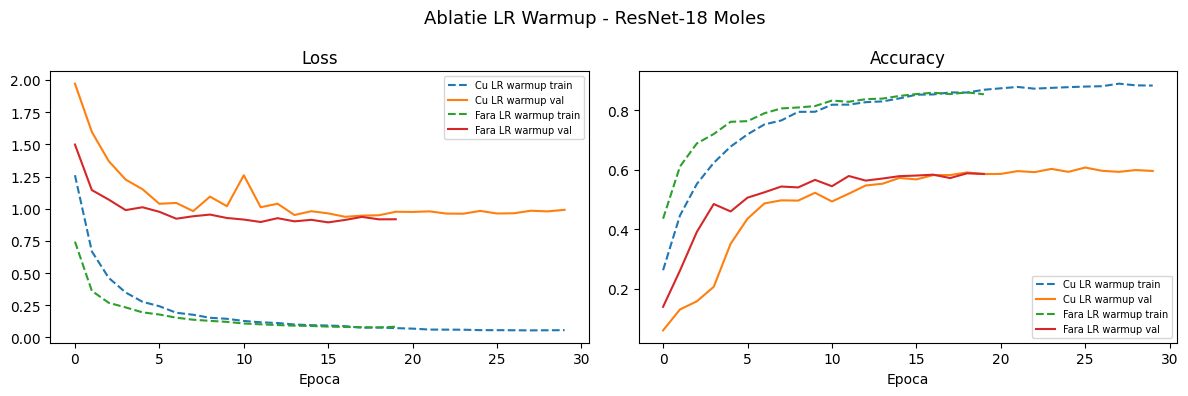


=== ResNet18 Moles Cu Warmup ===
Accuracy: 0.6076 | F1-macro: 0.5987 | F1-micro: 0.6076
Clasa         Precision   Recall       F1
  akiec           0.423    0.677    0.521
  bcc             0.558    0.835    0.669
  bkl             0.500    0.627    0.556
  df              0.621    0.783    0.692
  mel             0.260    0.757    0.387
  nv              0.988    0.550    0.707
  vasc            0.532    0.862    0.658


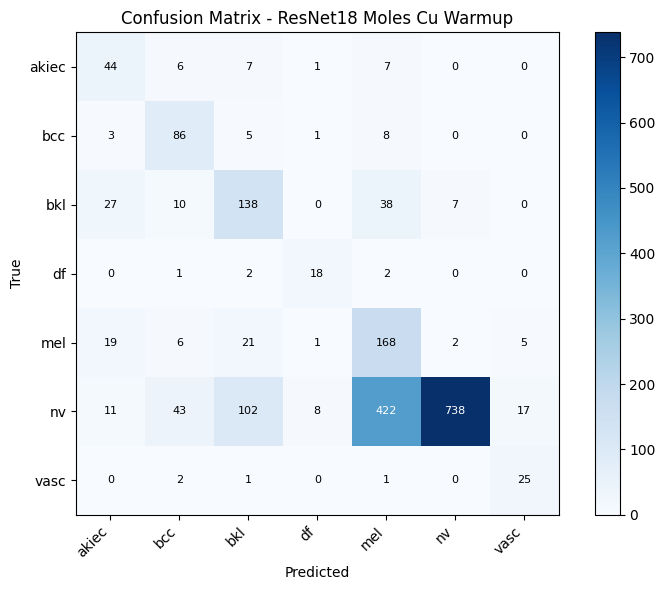

(0.6075886170743884, 0.5986597325044875, 0.6075886170740851)

In [22]:
# --- Ablatie: fara warmup MOLES -------------------------------------------
print('=== ResNet-18 Moles - fara warmup ===')
resnet_moles_nowarm = make_resnet18_full(len(MOLES_CLASSES)).to(device)
opt_rmnw = make_full_ft_optimizer(resnet_moles_nowarm, backbone_lr=5e-5, head_lr=5e-4)
sch_rmnw = CosineAnnealingLR(opt_rmnw, T_max=N_EPOCHS_FT2)

h_moles_nowarm = run_experiment(
    resnet_moles_nowarm, moles_ft_loader, moles_ft_val_ldr,
    crit_moles_ft, opt_rmnw, sch_rmnw,
    num_epochs=N_EPOCHS_FT2, device=device,
    run_name='resnet18_moles_nowarmup', log_dir=f'{BASE}/runs'
)

plot_history([h_moles_warmup, h_moles_nowarm], ['Cu LR warmup', 'Fara LR warmup'],
             title='Ablatie LR Warmup - ResNet-18 Moles',
             save_path=f'{BASE}/ablatie_warmup_moles.png')
report_metrics(resnet_moles_warmup, moles_ft_val_ldr, crit_moles_ft,
               MOLES_CLASSES, device, 'ResNet18 Moles Cu Warmup')


In [23]:
# --- Fine-tuning FACES - Full fine-tuning cu warmup -----------------------
face_ft_ds  = FacesDataset(f'{BASE}/splits/train.csv', make_resnet_tf(True, False))
face_ft_val = FacesDataset(f'{BASE}/splits/local_test.csv', resnet_face_val_tf)

face_ft_w       = get_class_weights(face_ft_ds, len(FACE_CLASSES), device)
crit_face_ft    = nn.CrossEntropyLoss(weight=face_ft_w)
face_ft_sampler = make_weighted_sampler(face_ft_ds, len(FACE_CLASSES))
face_ft_loader  = DataLoader(face_ft_ds,  batch_size=BS_FT, sampler=face_ft_sampler,
                              num_workers=4, drop_last=True, pin_memory=True)
face_ft_val_ldr = DataLoader(face_ft_val, batch_size=BS_FT, shuffle=False,
                              num_workers=4, pin_memory=True)

print('=== ResNet-18 Faces - full fine-tuning cu warmup ===')
resnet_face_warmup = make_resnet18_full(len(FACE_CLASSES)).to(device)
opt_rfw = make_full_ft_optimizer(resnet_face_warmup, backbone_lr=5e-5, head_lr=5e-4)
sch_rfw = make_warmup_cosine_scheduler(opt_rfw, WARMUP_EP, N_EPOCHS_FT)

h_face_warmup = run_experiment(
    resnet_face_warmup, face_ft_loader, face_ft_val_ldr,
    crit_face_ft, opt_rfw, sch_rfw,
    num_epochs=N_EPOCHS_FT, device=device,
    run_name='resnet18_face_warmup', log_dir=f'{BASE}/runs'
)


=== ResNet-18 Faces - full fine-tuning cu warmup ===
  Ep   5 | train loss=0.4105 acc=0.712 | val loss=1.3205 acc=0.529
  Ep  10 | train loss=0.1472 acc=0.878 | val loss=1.0760 acc=0.660
  Ep  15 | train loss=0.0778 acc=0.928 | val loss=0.8669 acc=0.746
  Ep  20 | train loss=0.0521 acc=0.952 | val loss=0.9242 acc=0.754
  Ep  25 | train loss=0.0372 acc=0.964 | val loss=0.8544 acc=0.776
  Ep  30 | train loss=0.0327 acc=0.968 | val loss=0.8549 acc=0.780


=== ResNet-18 Faces - fara warmup ===
  Ep   5 | train loss=0.2503 acc=0.811 | val loss=1.0799 acc=0.644
  Ep  10 | train loss=0.1180 acc=0.901 | val loss=0.8977 acc=0.728
  Ep  15 | train loss=0.0690 acc=0.935 | val loss=0.8943 acc=0.744
  Ep  20 | train loss=0.0645 acc=0.940 | val loss=0.8549 acc=0.753


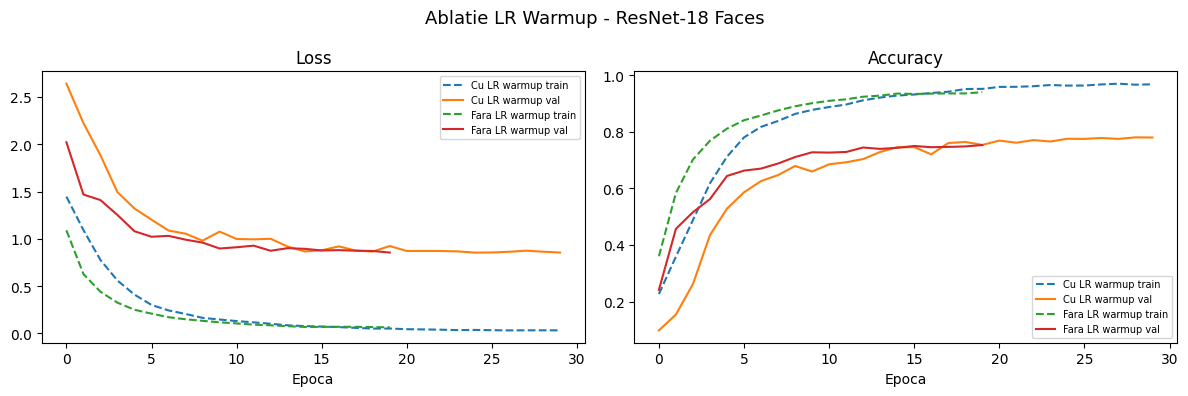


=== ResNet18 Faces Cu Warmup ===
Accuracy: 0.7806 | F1-macro: 0.6857 | F1-micro: 0.7806
Clasa         Precision   Recall       F1
  Surprise        0.766    0.829    0.796
  Fear            0.500    0.357    0.417
  Disgust         0.545    0.505    0.524
  Happiness       0.952    0.839    0.892
  Sadness         0.728    0.764    0.745
  Anger           0.632    0.752    0.687
  Neutral         0.692    0.791    0.738


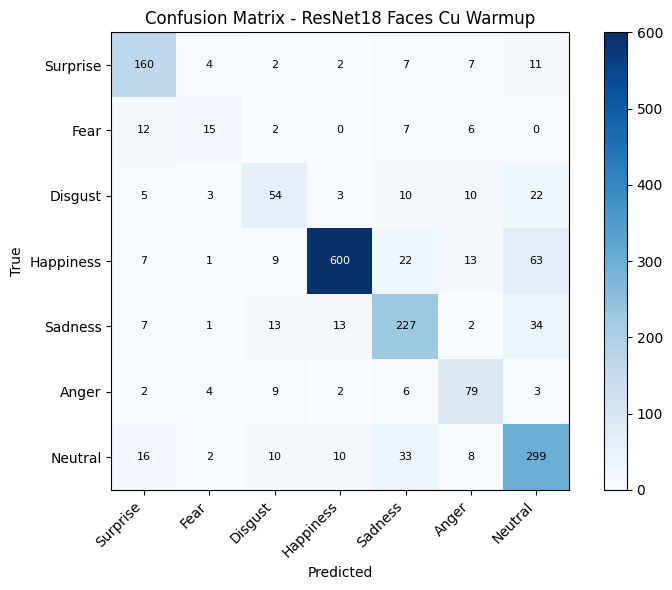

(0.7806205770277627, 0.6856948925298251, 0.7806205770273377)

In [24]:
# --- Ablatie: fara warmup FACES -------------------------------------------
print('=== ResNet-18 Faces - fara warmup ===')
resnet_face_nowarm = make_resnet18_full(len(FACE_CLASSES)).to(device)
opt_rfnw = make_full_ft_optimizer(resnet_face_nowarm, backbone_lr=5e-5, head_lr=5e-4)
sch_rfnw = CosineAnnealingLR(opt_rfnw, T_max=N_EPOCHS_FT2)

h_face_nowarm = run_experiment(
    resnet_face_nowarm, face_ft_loader, face_ft_val_ldr,
    crit_face_ft, opt_rfnw, sch_rfnw,
    num_epochs=N_EPOCHS_FT2, device=device,
    run_name='resnet18_face_nowarmup', log_dir=f'{BASE}/runs'
)

plot_history([h_face_warmup, h_face_nowarm], ['Cu LR warmup', 'Fara LR warmup'],
             title='Ablatie LR Warmup - ResNet-18 Faces',
             save_path=f'{BASE}/ablatie_warmup_faces.png')
report_metrics(resnet_face_warmup, face_ft_val_ldr, crit_face_ft,
               FACE_CLASSES, device, 'ResNet18 Faces Cu Warmup')


## 3.4b Fine-tuning MobileNet-v2


In [25]:
# --- MobileNet-v2 setup ---------------------------------------------------
def make_mobilenet_v2_full(num_classes):
    model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
    return model

def make_mobilenet_optimizer(model, backbone_lr=5e-5, head_lr=5e-4):
    head_params     = list(model.classifier.parameters())
    head_ids        = set(id(p) for p in head_params)
    backbone_params = [p for p in model.parameters() if id(p) not in head_ids]
    return optim.Adam([
        {'params': backbone_params, 'lr': backbone_lr},
        {'params': head_params,     'lr': head_lr},
    ], weight_decay=1e-4)

print('MobileNet-v2 setup ready.')


MobileNet-v2 setup ready.


In [26]:
# --- MobileNet-v2 MOLES - cu warmup (modelul principal) ------------------
print('=== MobileNet-v2 Moles - cu warmup ===')
mobilenet_moles_warmup = make_mobilenet_v2_full(len(MOLES_CLASSES)).to(device)
opt_mnmw = make_mobilenet_optimizer(mobilenet_moles_warmup, backbone_lr=5e-5, head_lr=5e-4)
sch_mnmw = make_warmup_cosine_scheduler(opt_mnmw, WARMUP_EP, N_EPOCHS_FT)

h_mn_moles_warmup = run_experiment(
    mobilenet_moles_warmup, moles_ft_loader, moles_ft_val_ldr,
    crit_moles_ft, opt_mnmw, sch_mnmw,
    num_epochs=N_EPOCHS_FT, device=device,
    run_name='mobilenet_moles_warmup', log_dir=f'{BASE}/runs'
)


=== MobileNet-v2 Moles - cu warmup ===
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to ~/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100.0%


  Ep   5 | train loss=0.3407 acc=0.630 | val loss=1.2678 acc=0.273
  Ep  10 | train loss=0.2010 acc=0.752 | val loss=1.0321 acc=0.416
  Ep  15 | train loss=0.1438 acc=0.803 | val loss=0.9632 acc=0.480
  Ep  20 | train loss=0.1082 acc=0.829 | val loss=0.9097 acc=0.533
  Ep  25 | train loss=0.0983 acc=0.833 | val loss=0.9052 acc=0.528
  Ep  30 | train loss=0.0913 acc=0.842 | val loss=0.8951 acc=0.546


=== MobileNet-v2 Moles - fara warmup ===
  Ep   5 | train loss=0.2568 acc=0.698 | val loss=0.9994 acc=0.406
  Ep  10 | train loss=0.1763 acc=0.764 | val loss=0.9433 acc=0.458
  Ep  15 | train loss=0.1384 acc=0.799 | val loss=0.9149 acc=0.505
  Ep  20 | train loss=0.1318 acc=0.812 | val loss=0.9410 acc=0.490


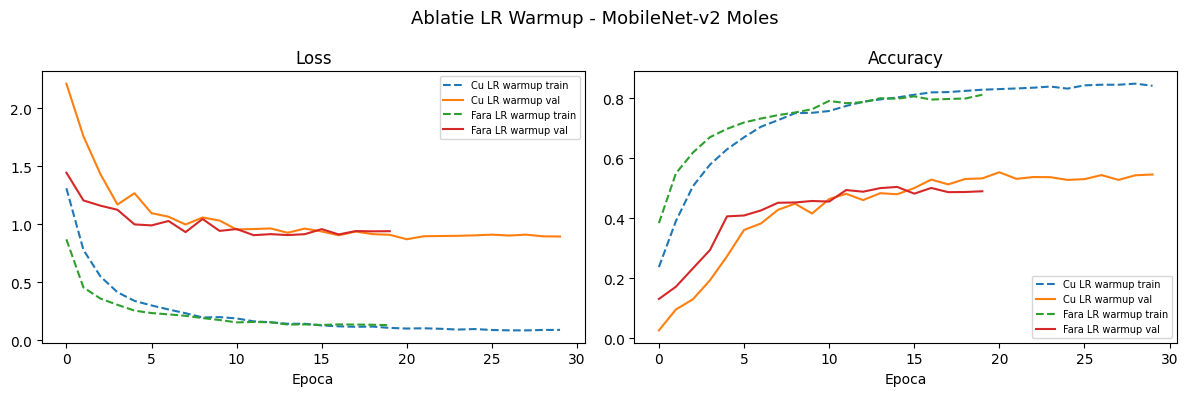


=== MobileNetV2 Moles Cu Warmup ===
Accuracy: 0.5537 | F1-macro: 0.5104 | F1-micro: 0.5537
Clasa         Precision   Recall       F1
  akiec           0.356    0.738    0.480
  bcc             0.427    0.796    0.556
  bkl             0.471    0.555    0.509
  df              0.339    0.870    0.488
  mel             0.238    0.658    0.350
  nv              0.984    0.496    0.659
  vasc            0.377    0.897    0.531


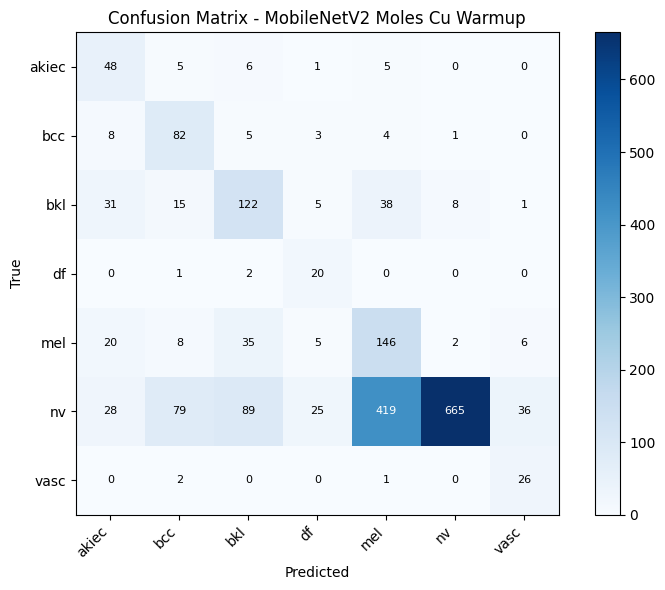

(0.5536694957563655, 0.510405662637568, 0.553669495756089)

In [27]:
# --- MobileNet-v2 MOLES - fara warmup (ablatie) --------------------------
print('=== MobileNet-v2 Moles - fara warmup ===')
mobilenet_moles_nowarm = make_mobilenet_v2_full(len(MOLES_CLASSES)).to(device)
opt_mnnmw = make_mobilenet_optimizer(mobilenet_moles_nowarm, backbone_lr=5e-5, head_lr=5e-4)
sch_mnnmw = CosineAnnealingLR(opt_mnnmw, T_max=N_EPOCHS_FT2)

h_mn_moles_nowarm = run_experiment(
    mobilenet_moles_nowarm, moles_ft_loader, moles_ft_val_ldr,
    crit_moles_ft, opt_mnnmw, sch_mnnmw,
    num_epochs=N_EPOCHS_FT2, device=device,
    run_name='mobilenet_moles_nowarmup', log_dir=f'{BASE}/runs'
)

plot_history([h_mn_moles_warmup, h_mn_moles_nowarm], ['Cu LR warmup', 'Fara LR warmup'],
             title='Ablatie LR Warmup - MobileNet-v2 Moles',
             save_path=f'{BASE}/ablatie_warmup_mobilenet_moles.png')
report_metrics(mobilenet_moles_warmup, moles_ft_val_ldr, crit_moles_ft,
               MOLES_CLASSES, device, 'MobileNetV2 Moles Cu Warmup')


In [28]:
# --- MobileNet-v2 FACES - cu warmup (modelul principal) ------------------
print('=== MobileNet-v2 Faces - cu warmup ===')
mobilenet_face_warmup = make_mobilenet_v2_full(len(FACE_CLASSES)).to(device)
opt_mnfw = make_mobilenet_optimizer(mobilenet_face_warmup, backbone_lr=5e-5, head_lr=5e-4)
sch_mnfw = make_warmup_cosine_scheduler(opt_mnfw, WARMUP_EP, N_EPOCHS_FT)

h_mn_face_warmup = run_experiment(
    mobilenet_face_warmup, face_ft_loader, face_ft_val_ldr,
    crit_face_ft, opt_mnfw, sch_mnfw,
    num_epochs=N_EPOCHS_FT, device=device,
    run_name='mobilenet_face_warmup', log_dir=f'{BASE}/runs'
)


=== MobileNet-v2 Faces - cu warmup ===
  Ep   5 | train loss=0.5964 acc=0.595 | val loss=1.6143 acc=0.443
  Ep  10 | train loss=0.2701 acc=0.795 | val loss=1.1678 acc=0.616
  Ep  15 | train loss=0.1591 acc=0.868 | val loss=1.0798 acc=0.676
  Ep  20 | train loss=0.1047 acc=0.904 | val loss=0.9664 acc=0.726
  Ep  25 | train loss=0.0929 acc=0.913 | val loss=0.9902 acc=0.727
  Ep  30 | train loss=0.0843 acc=0.918 | val loss=0.9549 acc=0.731


=== MobileNet-v2 Faces - fara warmup ===
  Ep   5 | train loss=0.4025 acc=0.712 | val loss=1.3586 acc=0.542
  Ep  10 | train loss=0.2211 acc=0.825 | val loss=1.1304 acc=0.643
  Ep  15 | train loss=0.1598 acc=0.867 | val loss=1.0941 acc=0.680
  Ep  20 | train loss=0.1519 acc=0.871 | val loss=1.0659 acc=0.684


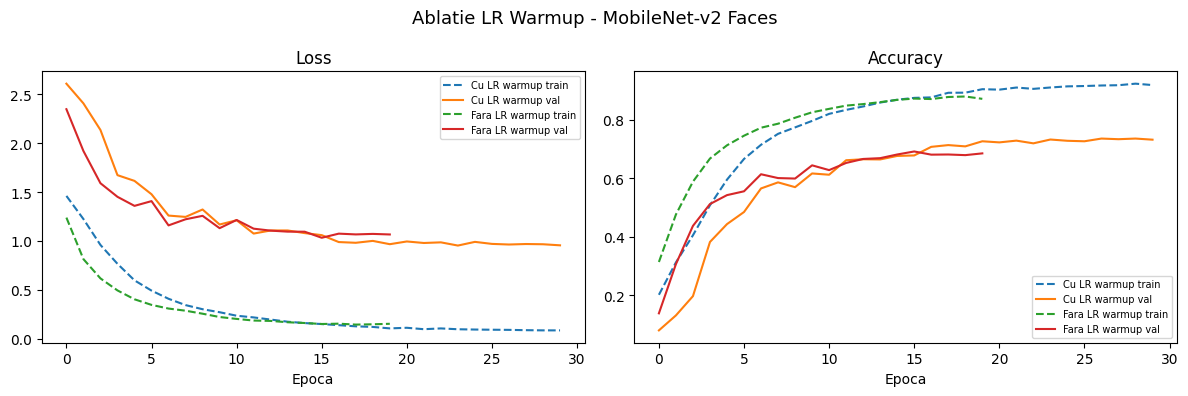


=== MobileNetV2 Faces Cu Warmup ===
Accuracy: 0.7349 | F1-macro: 0.6610 | F1-micro: 0.7349
Clasa         Precision   Recall       F1
  Surprise        0.692    0.839    0.759
  Fear            0.468    0.524    0.494
  Disgust         0.367    0.514    0.428
  Happiness       0.951    0.780    0.857
  Sadness         0.702    0.731    0.716
  Anger           0.648    0.771    0.704
  Neutral         0.662    0.675    0.668


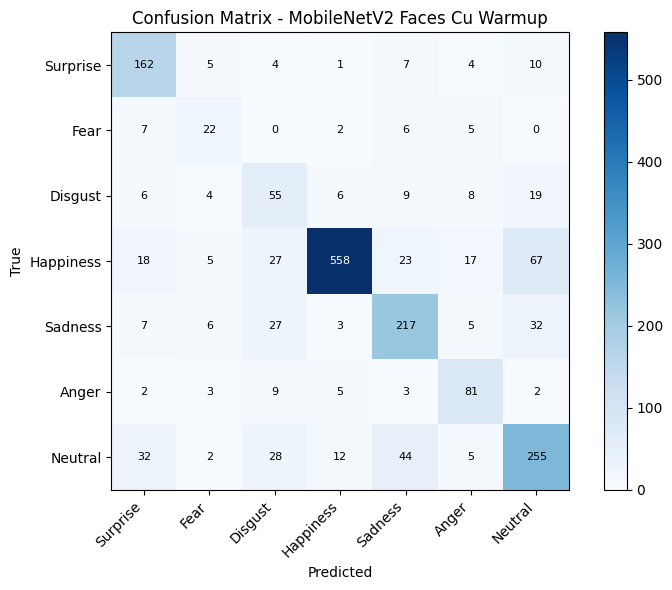

(0.7348938486663038, 0.6610366061605161, 0.7348938486659037)

In [29]:
# --- MobileNet-v2 FACES - fara warmup (ablatie) --------------------------
print('=== MobileNet-v2 Faces - fara warmup ===')
mobilenet_face_nowarm = make_mobilenet_v2_full(len(FACE_CLASSES)).to(device)
opt_mnfnw = make_mobilenet_optimizer(mobilenet_face_nowarm, backbone_lr=5e-5, head_lr=5e-4)
sch_mnfnw = CosineAnnealingLR(opt_mnfnw, T_max=N_EPOCHS_FT2)

h_mn_face_nowarm = run_experiment(
    mobilenet_face_nowarm, face_ft_loader, face_ft_val_ldr,
    crit_face_ft, opt_mnfnw, sch_mnfnw,
    num_epochs=N_EPOCHS_FT2, device=device,
    run_name='mobilenet_face_nowarmup', log_dir=f'{BASE}/runs'
)

plot_history([h_mn_face_warmup, h_mn_face_nowarm], ['Cu LR warmup', 'Fara LR warmup'],
             title='Ablatie LR Warmup - MobileNet-v2 Faces',
             save_path=f'{BASE}/ablatie_warmup_mobilenet_faces.png')
report_metrics(mobilenet_face_warmup, face_ft_val_ldr, crit_face_ft,
               FACE_CLASSES, device, 'MobileNetV2 Faces Cu Warmup')


## 3.5 Dezechilibru de clase

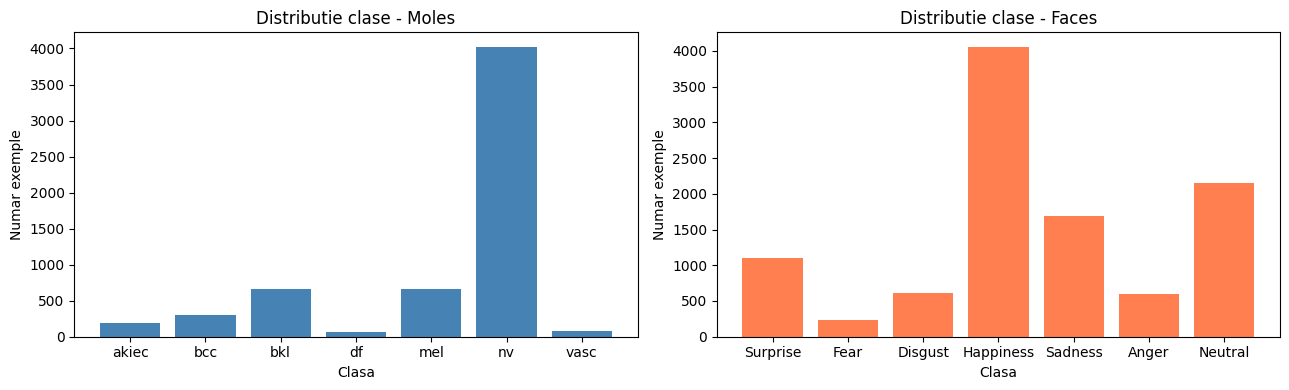

In [30]:
def get_class_weights(dataset, num_classes, device):
    """Calculeaza ponderi inverse frecventei pentru CrossEntropyLoss."""
    counts = np.bincount([lbl for _, lbl in dataset], minlength=num_classes).astype(float)
    weights = counts.sum() / (num_classes * counts)
    return torch.tensor(weights, dtype=torch.float).to(device)

def make_weighted_sampler(dataset, num_classes):
    """WeightedRandomSampler pentru balansare la nivel de batch."""
    labels = np.array([lbl for _, lbl in dataset])
    counts = np.bincount(labels, minlength=num_classes).astype(float)
    class_w = 1.0 / counts
    sample_w = class_w[labels]
    return WeightedRandomSampler(torch.from_numpy(sample_w).double(),
                                 num_samples=len(sample_w), replacement=True)

# Afisam distributia claselor
moles_counts = np.bincount([l for _, l in moles_train_ds], minlength=len(MOLES_CLASSES))
face_counts  = np.bincount([l for _, l in face_train_ds],  minlength=len(FACE_CLASSES))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(MOLES_CLASSES, moles_counts, color='steelblue')
axes[0].set_title('Distributie clase - Moles'); axes[0].set_xlabel('Clasa'); axes[0].set_ylabel('Numar exemple')
axes[1].bar(FACE_CLASSES, face_counts, color='coral')
axes[1].set_title('Distributie clase - Faces'); axes[1].set_xlabel('Clasa'); axes[1].set_ylabel('Numar exemple')
plt.tight_layout()
plt.savefig(f'{BASE}/class_distribution.png', bbox_inches='tight')
plt.show()

=== CNN Moles - fara tehnici dezechilibru ===
  Ep   5 | train loss=0.8730 acc=0.685 | val loss=0.8662 acc=0.699
  Ep  10 | train loss=0.8126 acc=0.699 | val loss=0.8153 acc=0.703
  Ep  15 | train loss=0.7762 acc=0.708 | val loss=0.7537 acc=0.720
  Ep  20 | train loss=0.7601 acc=0.721 | val loss=0.7425 acc=0.720
  Ep  25 | train loss=0.7395 acc=0.726 | val loss=0.7354 acc=0.723
  Ep  30 | train loss=0.7109 acc=0.735 | val loss=0.6861 acc=0.747
  Ep  35 | train loss=0.6948 acc=0.743 | val loss=0.6750 acc=0.753
  Ep  40 | train loss=0.6946 acc=0.739 | val loss=0.6728 acc=0.754
=== CNN Moles - cu weighted sampler + weighted loss ===
  Ep   5 | train loss=1.0150 acc=0.321 | val loss=2.1144 acc=0.068
  Ep  10 | train loss=0.8645 acc=0.368 | val loss=1.8021 acc=0.084
  Ep  15 | train loss=0.7918 acc=0.407 | val loss=1.8495 acc=0.082
  Ep  20 | train loss=0.7168 acc=0.440 | val loss=1.8208 acc=0.128
  Ep  25 | train loss=0.6509 acc=0.466 | val loss=1.7263 acc=0.102
  Ep  30 | train loss=0.621

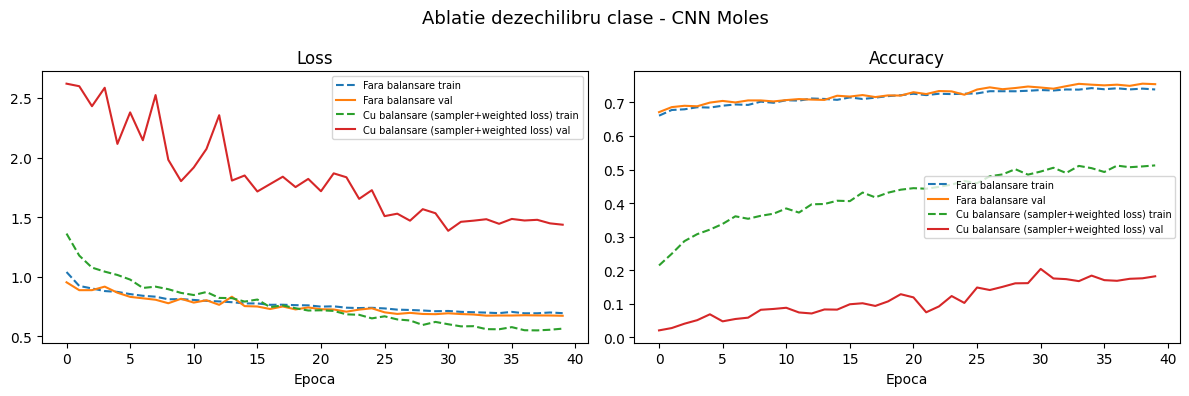


=== CNN Moles Fara balansare ===
Accuracy: 0.7559 | F1-macro: 0.4547 | F1-micro: 0.7559
Clasa         Precision   Recall       F1
  akiec           0.361    0.338    0.349
  bcc             0.525    0.408    0.459
  bkl             0.526    0.409    0.460
  df              0.000    0.000    0.000
  mel             0.503    0.378    0.432
  nv              0.838    0.941    0.887
  vasc            0.778    0.483    0.596


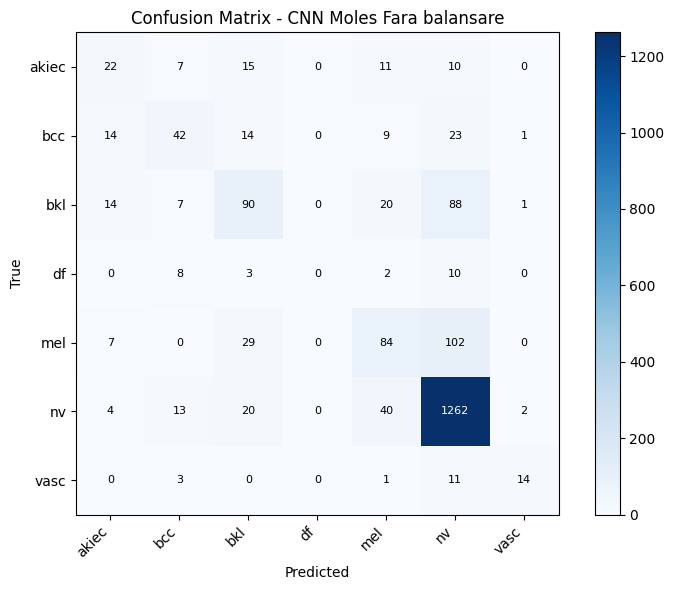


=== CNN Moles Cu balansare ===
Accuracy: 0.2037 | F1-macro: 0.1950 | F1-micro: 0.2037
Clasa         Precision   Recall       F1
  akiec           0.127    0.785    0.219
  bcc             0.362    0.204    0.261
  bkl             0.333    0.068    0.113
  df              0.033    0.783    0.064
  mel             0.210    0.523    0.299
  nv              1.000    0.119    0.213
  vasc            0.109    0.931    0.196


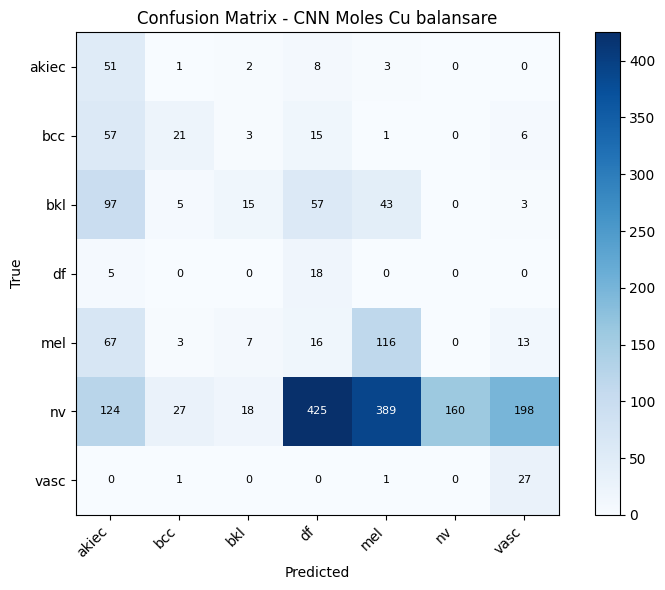

(0.2036944583125312, 0.19503091293516212, 0.20369445831242952)

In [31]:
# --- CNN Moles: fara vs cu tehnici dezechilibru -------------------------------
print('=== CNN Moles - fara tehnici dezechilibru ===')
aug_ds_moles = MolesDataset(f'{BASE}/train.csv', f'{BASE}/train', make_moles_tf(True, True))
loader_nobal = DataLoader(aug_ds_moles, batch_size=BS, shuffle=True, num_workers=2, drop_last=True)

m_nobal = CNN(len(MOLES_CLASSES), first_kernel=5, use_bn=True).to(device)
opt_nb = optim.Adam(m_nobal.parameters(), lr=1e-3, weight_decay=1e-4)
h_nobal = run_experiment(m_nobal, loader_nobal, moles_val_loader, crit_moles, opt_nb,
    optim.lr_scheduler.CosineAnnealingLR(opt_nb, T_max=N_EPOCHS_CNN),
    num_epochs=N_EPOCHS_CNN, device=device,
    run_name='cnn_moles_nobal', log_dir=f'{BASE}/runs')

print('=== CNN Moles - cu weighted sampler + weighted loss ===')
sampler_moles = make_weighted_sampler(aug_ds_moles, len(MOLES_CLASSES))
loader_bal    = DataLoader(aug_ds_moles, batch_size=BS, sampler=sampler_moles, num_workers=2, drop_last=True)
moles_w       = get_class_weights(moles_train_ds, len(MOLES_CLASSES), device)
crit_moles_w  = nn.CrossEntropyLoss(weight=moles_w)

m_bal = CNN(len(MOLES_CLASSES), first_kernel=5, use_bn=True).to(device)
opt_b = optim.Adam(m_bal.parameters(), lr=1e-3, weight_decay=1e-4)
h_bal = run_experiment(m_bal, loader_bal, moles_val_loader, crit_moles_w, opt_b,
    optim.lr_scheduler.CosineAnnealingLR(opt_b, T_max=N_EPOCHS_CNN),
    num_epochs=N_EPOCHS_CNN, device=device,
    run_name='cnn_moles_balanced', log_dir=f'{BASE}/runs')

plot_history([h_nobal, h_bal], ['Fara balansare', 'Cu balansare (sampler+weighted loss)'],
             title='Ablatie dezechilibru clase - CNN Moles',
             save_path=f'{BASE}/ablatie_imbalance_moles.png')

report_metrics(m_nobal, moles_val_loader, crit_moles, MOLES_CLASSES, device, 'CNN Moles Fara balansare')
report_metrics(m_bal,   moles_val_loader, crit_moles, MOLES_CLASSES, device, 'CNN Moles Cu balansare')

=== CNN Faces - fara tehnici dezechilibru ===
  Ep   5 | train loss=1.5589 acc=0.410 | val loss=1.5442 acc=0.409
  Ep  10 | train loss=1.3114 acc=0.520 | val loss=1.2927 acc=0.539
  Ep  15 | train loss=1.1115 acc=0.606 | val loss=1.1685 acc=0.579
  Ep  20 | train loss=0.9875 acc=0.657 | val loss=1.2222 acc=0.533
  Ep  25 | train loss=0.9025 acc=0.688 | val loss=0.9690 acc=0.639
  Ep  30 | train loss=0.8436 acc=0.704 | val loss=1.0216 acc=0.628
  Ep  35 | train loss=0.8025 acc=0.724 | val loss=0.9302 acc=0.660
  Ep  40 | train loss=0.7825 acc=0.728 | val loss=0.9180 acc=0.668
=== CNN Faces - cu weighted sampler + weighted loss ===
  Ep   5 | train loss=1.4354 acc=0.198 | val loss=2.9139 acc=0.031
  Ep  10 | train loss=1.2904 acc=0.271 | val loss=2.5874 acc=0.094
  Ep  15 | train loss=1.1595 acc=0.302 | val loss=2.4682 acc=0.079
  Ep  20 | train loss=1.0502 acc=0.352 | val loss=2.3914 acc=0.111
  Ep  25 | train loss=0.9430 acc=0.395 | val loss=2.2390 acc=0.134
  Ep  30 | train loss=0.871

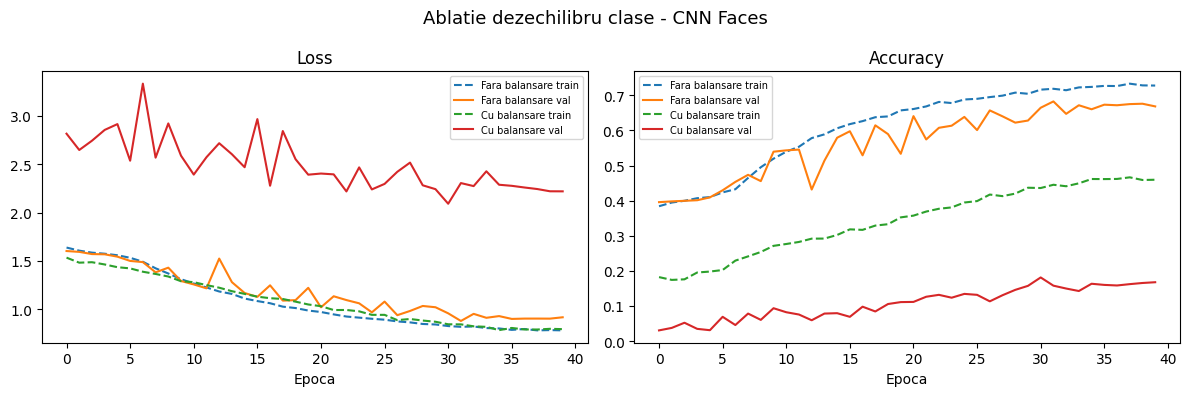


=== CNN Faces Fara balansare ===
Accuracy: 0.6826 | F1-macro: 0.4877 | F1-micro: 0.6826
Clasa         Precision   Recall       F1
  Surprise        0.818    0.699    0.754
  Fear            0.667    0.048    0.089
  Disgust         0.750    0.028    0.054
  Happiness       0.857    0.846    0.852
  Sadness         0.499    0.704    0.584
  Anger           0.409    0.514    0.456
  Neutral         0.603    0.651    0.626


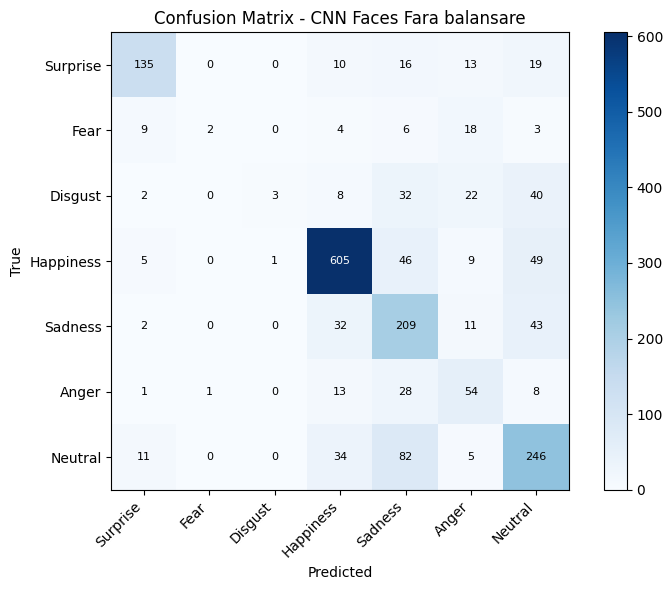


=== CNN Faces Cu balansare ===
Accuracy: 0.1813 | F1-macro: 0.2160 | F1-micro: 0.1813
Clasa         Precision   Recall       F1
  Surprise        0.500    0.492    0.496
  Fear            0.117    0.738    0.203
  Disgust         0.081    0.776    0.146
  Happiness       0.000    0.000    0.000
  Sadness         0.429    0.040    0.074
  Anger           0.291    0.590    0.390
  Neutral         0.435    0.132    0.203


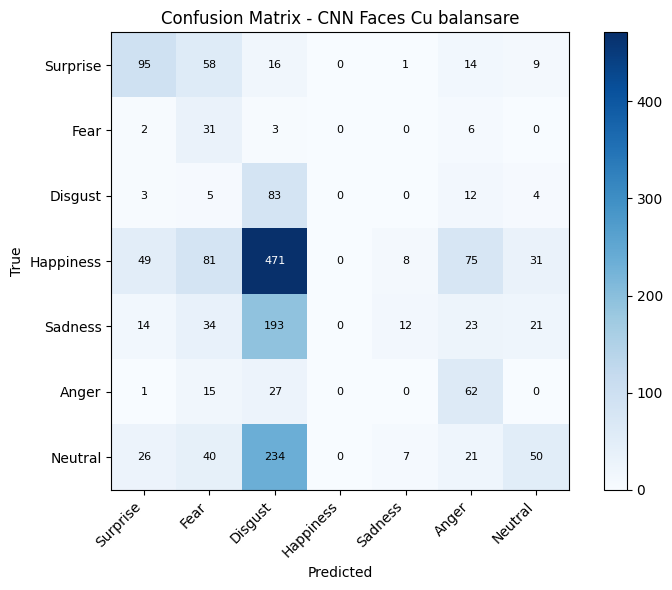

(0.18127381600435494, 0.21595791815332907, 0.18127381600425624)

In [32]:
# --- CNN Faces: fara vs cu tehnici dezechilibru -------------------------------
print('=== CNN Faces - fara tehnici dezechilibru ===')
aug_ds_face = FacesDataset(f'{BASE}/splits/train.csv', make_face_tf(True, True))
loader_face_nobal = DataLoader(aug_ds_face, batch_size=BS, shuffle=True, num_workers=2, drop_last=True)

f_nobal = CNN(len(FACE_CLASSES), first_kernel=3, use_bn=True).to(device)
opt_fnb = optim.Adam(f_nobal.parameters(), lr=1e-3, weight_decay=1e-4)
h_face_nobal = run_experiment(f_nobal, loader_face_nobal, face_val_loader, crit_face, opt_fnb,
    optim.lr_scheduler.CosineAnnealingLR(opt_fnb, T_max=N_EPOCHS_CNN),
    num_epochs=N_EPOCHS_CNN, device=device,
    run_name='cnn_face_nobal', log_dir=f'{BASE}/runs')

print('=== CNN Faces - cu weighted sampler + weighted loss ===')
sampler_face    = make_weighted_sampler(aug_ds_face, len(FACE_CLASSES))
loader_face_bal = DataLoader(aug_ds_face, batch_size=BS, sampler=sampler_face, num_workers=2, drop_last=True)
face_w          = get_class_weights(face_train_ds, len(FACE_CLASSES), device)
crit_face_w     = nn.CrossEntropyLoss(weight=face_w)

f_bal = CNN(len(FACE_CLASSES), first_kernel=3, use_bn=True).to(device)
opt_fb = optim.Adam(f_bal.parameters(), lr=1e-3, weight_decay=1e-4)
h_face_bal = run_experiment(f_bal, loader_face_bal, face_val_loader, crit_face_w, opt_fb,
    optim.lr_scheduler.CosineAnnealingLR(opt_fb, T_max=N_EPOCHS_CNN),
    num_epochs=N_EPOCHS_CNN, device=device,
    run_name='cnn_face_balanced', log_dir=f'{BASE}/runs')

plot_history([h_face_nobal, h_face_bal], ['Fara balansare', 'Cu balansare'],
             title='Ablatie dezechilibru clase - CNN Faces',
             save_path=f'{BASE}/ablatie_imbalance_faces.png')

report_metrics(f_nobal, face_val_loader, crit_face,  FACE_CLASSES, device, 'CNN Faces Fara balansare')
report_metrics(f_bal,   face_val_loader, crit_face,  FACE_CLASSES, device, 'CNN Faces Cu balansare')

## Generare predictii Kaggle

In [40]:
import csv
from collections import Counter

MOLES_IDX2CLASS_SUB = {0:'akiec',1:'bcc',2:'bkl',3:'df',4:'mel',5:'nv',6:'vasc'}

@torch.no_grad()
def predict_kaggle(model, loader, device):
    """Predictie simpla fara TTA."""
    model.eval()
    ids, preds = [], []
    for imgs, names in loader:
        imgs = imgs.to(device)
        out = model(imgs)
        p = out.argmax(1).cpu().tolist()
        preds.extend(p)
        ids.extend(names if isinstance(names, list) else list(names))
    return ids, preds

@torch.no_grad()
def predict_kaggle_tta(model, dataset, tf_val, tf_aug, device, n_aug=5):
    """Test-Time Augmentation: mediem probabilitatile pe n_aug versiuni augmentate."""
    model.eval()
    ids, all_probs = [], []

    # Colectam ID-urile
    loader_val = DataLoader(dataset, batch_size=64, shuffle=False, num_workers=4)
    for imgs, names in loader_val:
        ids.extend(names if isinstance(names, list) else list(names))

    # Rulam de n_aug ori cu augmentari diferite + 1 data fara augmentare
    all_logits = None
    for aug_i in range(n_aug + 1):
        tf = tf_val if aug_i == 0 else tf_aug
        dataset.transform = tf
        loader = DataLoader(dataset, batch_size=64, shuffle=False, num_workers=4)
        logits_list = []
        for imgs, _ in loader:
            imgs = imgs.to(device)
            out = model(imgs)
            logits_list.append(torch.softmax(out, dim=1).cpu())
        logits_epoch = torch.cat(logits_list, dim=0)
        if all_logits is None:
            all_logits = logits_epoch
        else:
            all_logits += logits_epoch

    # Restauram transform-ul original
    dataset.transform = tf_val
    preds = all_logits.argmax(dim=1).tolist()
    return ids, preds

def save_submission(ids, preds, path, is_moles=False):
    with open(path, 'w', newline='') as f:
        w = csv.writer(f)
        if is_moles:
            w.writerow(['imagine', 'diagnostic'])
            for img_id, pred in zip(ids, preds):
                w.writerow([img_id, MOLES_IDX2CLASS_SUB[pred]])
        else:
            w.writerow(['id', 'label'])
            for img_id, pred in zip(ids, preds):
                w.writerow([img_id, pred + 1])  # 0-indexed -> 1-indexed
    print(f'Salvat: {path} ({len(ids)} rows)')
    print('Distributie:', dict(sorted(Counter(preds).items())))

# Loaders pentru predictie simpla (fara TTA)
moles_kag_ds      = MolesDataset(f'{BASE}/kaggle_test.csv', f'{BASE}/kaggle_test',
                                   resnet_moles_val_tf, is_test=True)
face_rem_ds       = FacesDataset(f'{BASE}/splits/remote_test.csv', resnet_face_val_tf, is_test=True)
moles_kag_mlp_ds  = MolesDataset(f'{BASE}/kaggle_test.csv', f'{BASE}/kaggle_test',
                                   moles_val_tf, is_test=True)
face_rem_mlp_ds   = FacesDataset(f'{BASE}/splits/remote_test.csv', face_val_tf, is_test=True)

moles_kag_ldr     = DataLoader(moles_kag_ds,     batch_size=64, shuffle=False, num_workers=4)
face_rem_ldr      = DataLoader(face_rem_ds,       batch_size=64, shuffle=False, num_workers=4)
moles_kag_mlp_ldr = DataLoader(moles_kag_mlp_ds, batch_size=64, shuffle=False, num_workers=4)
face_rem_mlp_ldr  = DataLoader(face_rem_mlp_ds,  batch_size=64, shuffle=False, num_workers=4)

print('Loaders gata.')


Loaders gata.


In [41]:
# --- SUBMISSION MLP - Moles (fara TTA) ----------------------------------
ids_m, preds_m = predict_kaggle(mlp_moles_drop, moles_kag_mlp_ldr, device)
save_submission(ids_m, preds_m, f'{BASE}/submission_mlp_moles.csv', is_moles=True)

# --- SUBMISSION MLP - Faces (fara TTA) -----------------------------------
ids_f, preds_f = predict_kaggle(mlp_face_drop, face_rem_mlp_ldr, device)
save_submission(ids_f, preds_f, f'{BASE}/submission_mlp_faces.csv')

# --- SUBMISSION CNN - Moles (fara TTA) -----------------------------------
moles_kag_cnn_ldr = DataLoader(
    MolesDataset(f'{BASE}/kaggle_test.csv', f'{BASE}/kaggle_test',
                 make_moles_tf(geom=True, color=True), is_test=True),
    batch_size=64, shuffle=False, num_workers=4)
ids_m, preds_m = predict_kaggle(cnn_moles_bn, moles_kag_cnn_ldr, device)
save_submission(ids_m, preds_m, f'{BASE}/submission_cnn_moles.csv', is_moles=True)

# --- SUBMISSION CNN - Faces (fara TTA) -----------------------------------
face_rem_cnn_ldr = DataLoader(
    FacesDataset(f'{BASE}/splits/remote_test.csv',
                 make_face_tf(geom=True, color=True), is_test=True),
    batch_size=64, shuffle=False, num_workers=4)
ids_f, preds_f = predict_kaggle(cnn_face_bn, face_rem_cnn_ldr, device)
save_submission(ids_f, preds_f, f'{BASE}/submission_cnn_faces.csv')

# --- SUBMISSION ResNet-18 - Moles (cu TTA) --------------------------------
print('ResNet Moles TTA...')
moles_kag_tta_ds = MolesDataset(f'{BASE}/kaggle_test.csv', f'{BASE}/kaggle_test',
                                  resnet_moles_val_tf, is_test=True)
ids_m, preds_m = predict_kaggle_tta(
    resnet_moles_warmup, moles_kag_tta_ds,
    resnet_moles_val_tf, make_resnet_tf(augment=True, is_moles=True),
    device, n_aug=5)
save_submission(ids_m, preds_m, f'{BASE}/submission_resnet_moles.csv', is_moles=True)

# --- SUBMISSION ResNet-18 - Faces (cu TTA) --------------------------------
print('ResNet Faces TTA...')
face_rem_tta_ds = FacesDataset(f'{BASE}/splits/remote_test.csv', resnet_face_val_tf, is_test=True)
ids_f, preds_f = predict_kaggle_tta(
    resnet_face_warmup, face_rem_tta_ds,
    resnet_face_val_tf, make_resnet_tf(augment=True, is_moles=False),
    device, n_aug=5)
save_submission(ids_f, preds_f, f'{BASE}/submission_resnet_faces.csv')

# --- SUBMISSION MobileNet - Moles (cu TTA) --------------------------------
print('MobileNet Moles TTA...')
moles_kag_tta_ds2 = MolesDataset(f'{BASE}/kaggle_test.csv', f'{BASE}/kaggle_test',
                                   resnet_moles_val_tf, is_test=True)
ids_m, preds_m = predict_kaggle_tta(
    mobilenet_moles_warmup, moles_kag_tta_ds2,
    resnet_moles_val_tf, make_resnet_tf(augment=True, is_moles=True),
    device, n_aug=5)
save_submission(ids_m, preds_m, f'{BASE}/submission_mobilenet_moles.csv', is_moles=True)

# --- SUBMISSION MobileNet - Faces (cu TTA) --------------------------------
print('MobileNet Faces TTA...')
face_rem_tta_ds2 = FacesDataset(f'{BASE}/splits/remote_test.csv', resnet_face_val_tf, is_test=True)
ids_f, preds_f = predict_kaggle_tta(
    mobilenet_face_warmup, face_rem_tta_ds2,
    resnet_face_val_tf, make_resnet_tf(augment=True, is_moles=False),
    device, n_aug=5)
save_submission(ids_f, preds_f, f'{BASE}/submission_mobilenet_faces.csv')

print('\nToate submission-urile generate cu TTA.')


Salvat: ./submission_mlp_moles.csv (2003 rows)
Distributie: {0: 54, 1: 111, 2: 198, 3: 7, 4: 149, 5: 1456, 6: 28}
Salvat: ./submission_mlp_faces.csv (3068 rows)
Distributie: {0: 324, 1: 45, 2: 133, 3: 1235, 4: 438, 5: 137, 6: 756}
Salvat: ./submission_cnn_moles.csv (2003 rows)
Distributie: {0: 28, 1: 100, 2: 184, 4: 147, 5: 1523, 6: 21}
Salvat: ./submission_cnn_faces.csv (3068 rows)
Distributie: {0: 346, 2: 4, 3: 1342, 4: 507, 5: 169, 6: 700}
ResNet Moles TTA...
Salvat: ./submission_resnet_moles.csv (2003 rows)
Distributie: {0: 114, 1: 150, 2: 327, 3: 30, 4: 611, 5: 729, 6: 42}
ResNet Faces TTA...
Salvat: ./submission_resnet_faces.csv (3068 rows)
Distributie: {0: 352, 1: 64, 2: 149, 3: 1083, 4: 518, 5: 173, 6: 729}
MobileNet Moles TTA...
Salvat: ./submission_mobilenet_moles.csv (2003 rows)
Distributie: {0: 114, 1: 156, 2: 342, 3: 41, 4: 604, 5: 693, 6: 53}
MobileNet Faces TTA...
Salvat: ./submission_mobilenet_faces.csv (3068 rows)
Distributie: {0: 388, 1: 72, 2: 226, 3: 997, 4: 543, 5:

In [42]:
# --- Salvare modele -------------------------------------------------------
torch.save(resnet_moles_warmup.state_dict(),     f'{BASE}/best_resnet18_moles.pt')
torch.save(resnet_face_warmup.state_dict(),      f'{BASE}/best_resnet18_faces.pt')
torch.save(mobilenet_moles_warmup.state_dict(),  f'{BASE}/best_mobilenet_moles.pt')
torch.save(mobilenet_face_warmup.state_dict(),   f'{BASE}/best_mobilenet_faces.pt')
torch.save(cnn_moles_bn.state_dict(),            f'{BASE}/best_cnn_moles.pt')
torch.save(cnn_face_bn.state_dict(),             f'{BASE}/best_cnn_faces.pt')
torch.save(mlp_moles_drop.state_dict(),          f'{BASE}/best_mlp_moles.pt')
torch.save(mlp_face_drop.state_dict(),           f'{BASE}/best_mlp_faces.pt')
print('Toate modelele salvate.')


Toate modelele salvate.


## BONUS: Curriculum Learning pe Faces

Implementam doua strategii din Sectiunea 7 a tutorialului:
- **Strategia 1**: Pacing function - expunem modelului progresiv mai multe exemple
- **Strategia 2**: Self-paced learning - selectam exemple cu loss mic (usoare) si crestem pragul

Dificultatea unui exemplu = loss-ul modelului pe acel exemplu (auto-paced).
Incepem cu 30% din date (cele mai usoare) si ajungem la 100% dupa jumatate din epoci.
Comparam cu baseline-ul CNN antrenat normal (fara curriculum).

In [43]:
# --- Utilitati Curriculum Learning (Sectiunea 7 din tutorial) ---

def pacing(epoch, total_epochs, start_frac=0.3):
    """Functie de pacing liniara: de la start_frac la 1.0 in prima jumatate."""
    return min(1.0, start_frac + (1 - start_frac) * (epoch / (total_epochs * 0.5)))

@torch.no_grad()
def per_sample_losses(model, dataset, device, batch_size=128):
    """Calculeaza loss-ul per exemplu cu modelul curent."""
    model.eval()
    criterion_nr = nn.CrossEntropyLoss(reduction='none')
    losses = []
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        out = model(imgs)
        l = criterion_nr(out, labels)
        losses.append(l.cpu())
    return torch.cat(losses)

print('Curriculum utils defined.')

Curriculum utils defined.


### Strategia 1: Pacing Function (filtrare dupa dificultate pre-calculata)

In [44]:
N_EPOCHS_CL = 40
face_cl_tf = make_face_tf(geom=True, color=True)
face_cl_ds = FacesDataset(f'{BASE}/splits/train.csv', face_cl_tf)

# Calculam dificultatea initiala cu modelul CNN antrenat anterior
# (cnn_face_bn - cel mai bun model CNN de la sectiunea 3.3)
print('Calculam dificultatea initiala...')
initial_losses = per_sample_losses(cnn_face_bn, face_cl_ds, device)
# Sortam indicii dupa dificultate: cei cu loss mic = exemple usoare
sorted_indices = torch.argsort(initial_losses).tolist()
print(f'Loss min: {initial_losses.min():.4f}, max: {initial_losses.max():.4f}')

# Antrenam cu curriculum pacing
model_cl1 = CNN(len(FACE_CLASSES), first_kernel=3, use_bn=True).to(device)
opt_cl1 = optim.Adam(model_cl1.parameters(), lr=1e-3, weight_decay=1e-4)
sch_cl1 = CosineAnnealingLR(opt_cl1, T_max=N_EPOCHS_CL)
crit_cl = nn.CrossEntropyLoss()

writer_cl1 = SummaryWriter(log_dir=f'{BASE}/runs/curriculum_pacing_faces')
hist_cl1 = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_val_acc_cl1 = 0
best_state_cl1 = None

for epoch in range(N_EPOCHS_CL):
    frac = pacing(epoch, N_EPOCHS_CL, start_frac=0.3)
    n_use = max(1, int(frac * len(sorted_indices)))
    current_indices = sorted_indices[:n_use]
    subset = Subset(face_cl_ds, current_indices)
    loader = DataLoader(subset, batch_size=BS, shuffle=True, num_workers=2, drop_last=True)

    tr_loss, tr_acc = train_one_epoch(model_cl1, loader, crit_cl, opt_cl1, device)
    va_loss, va_acc, _, _ = evaluate(model_cl1, face_val_loader, crit_cl, device)
    sch_cl1.step()

    hist_cl1['train_loss'].append(tr_loss)
    hist_cl1['train_acc'].append(tr_acc)
    hist_cl1['val_loss'].append(va_loss)
    hist_cl1['val_acc'].append(va_acc)

    writer_cl1.add_scalar('Loss/train', tr_loss, epoch)
    writer_cl1.add_scalar('Loss/val', va_loss, epoch)
    writer_cl1.add_scalar('Acc/train', tr_acc, epoch)
    writer_cl1.add_scalar('Acc/val', va_acc, epoch)
    writer_cl1.add_scalar('Pacing/frac', frac, epoch)
    writer_cl1.add_scalar('Pacing/n_samples', n_use, epoch)

    if va_acc > best_val_acc_cl1:
        best_val_acc_cl1 = va_acc
        best_state_cl1 = {k: v.cpu().clone() for k, v in model_cl1.state_dict().items()}

    if (epoch + 1) % 5 == 0:
        print(f'  Ep {epoch+1:3d} | frac={frac:.2f} n={n_use} | '
              f'train loss={tr_loss:.4f} acc={tr_acc:.3f} | val loss={va_loss:.4f} acc={va_acc:.3f}')

writer_cl1.close()
model_cl1.load_state_dict(best_state_cl1)
print('Curriculum pacing done.')

Calculam dificultatea initiala...
Loss min: 0.0000, max: 7.9252
  Ep   5 | frac=0.44 n=4590 | train loss=0.8386 acc=0.726 | val loss=2.6131 acc=0.389
  Ep  10 | frac=0.61 n=6416 | train loss=0.9501 acc=0.631 | val loss=1.9967 acc=0.437
  Ep  15 | frac=0.79 n=8242 | train loss=0.7809 acc=0.708 | val loss=1.5307 acc=0.567
  Ep  20 | frac=0.96 n=10068 | train loss=0.9536 acc=0.663 | val loss=1.2158 acc=0.563
  Ep  25 | frac=1.00 n=10434 | train loss=0.9372 acc=0.680 | val loss=0.9487 acc=0.660
  Ep  30 | frac=1.00 n=10434 | train loss=0.8531 acc=0.707 | val loss=0.9314 acc=0.671
  Ep  35 | frac=1.00 n=10434 | train loss=0.8195 acc=0.718 | val loss=0.9183 acc=0.677
  Ep  40 | frac=1.00 n=10434 | train loss=0.7980 acc=0.727 | val loss=0.9147 acc=0.682
Curriculum pacing done.


### Strategia 2: Self-Paced Learning (loss-ul propriu al modelului)

In [45]:
model_cl2 = CNN(len(FACE_CLASSES), first_kernel=3, use_bn=True).to(device)
opt_cl2 = optim.Adam(model_cl2.parameters(), lr=1e-3, weight_decay=1e-4)
sch_cl2 = CosineAnnealingLR(opt_cl2, T_max=N_EPOCHS_CL)

writer_cl2 = SummaryWriter(log_dir=f'{BASE}/runs/curriculum_selfpaced_faces')
hist_cl2 = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_val_acc_cl2 = 0
best_state_cl2 = None

for epoch in range(N_EPOCHS_CL):
    # Recalculam loss-ul per exemplu cu modelul curent
    losses = per_sample_losses(model_cl2, face_cl_ds, device)
    # Pragul creste cu epoca: incepem cu 30% cele mai usoare
    q = min(1.0, 0.3 + 0.018 * epoch)  # ajunge la 1.0 in ~39 epoci
    threshold = torch.quantile(losses, q)
    easy_idx = (losses <= threshold).nonzero(as_tuple=True)[0].tolist()

    subset = Subset(face_cl_ds, easy_idx)
    loader = DataLoader(subset, batch_size=BS, shuffle=True, num_workers=2, drop_last=True)

    tr_loss, tr_acc = train_one_epoch(model_cl2, loader, crit_cl, opt_cl2, device)
    va_loss, va_acc, _, _ = evaluate(model_cl2, face_val_loader, crit_cl, device)
    sch_cl2.step()

    hist_cl2['train_loss'].append(tr_loss)
    hist_cl2['train_acc'].append(tr_acc)
    hist_cl2['val_loss'].append(va_loss)
    hist_cl2['val_acc'].append(va_acc)

    writer_cl2.add_scalar('Loss/train', tr_loss, epoch)
    writer_cl2.add_scalar('Loss/val', va_loss, epoch)
    writer_cl2.add_scalar('Acc/train', tr_acc, epoch)
    writer_cl2.add_scalar('Acc/val', va_acc, epoch)
    writer_cl2.add_scalar('SelfPaced/n_samples', len(easy_idx), epoch)
    writer_cl2.add_scalar('SelfPaced/threshold', threshold.item(), epoch)

    if va_acc > best_val_acc_cl2:
        best_val_acc_cl2 = va_acc
        best_state_cl2 = {k: v.cpu().clone() for k, v in model_cl2.state_dict().items()}

    if (epoch + 1) % 5 == 0:
        print(f'  Ep {epoch+1:3d} | q={q:.2f} n={len(easy_idx)} | '
              f'train loss={tr_loss:.4f} acc={tr_acc:.3f} | val loss={va_loss:.4f} acc={va_acc:.3f}')

writer_cl2.close()
model_cl2.load_state_dict(best_state_cl2)
print('Self-paced done.')

  Ep   5 | q=0.37 n=3882 | train loss=0.3444 acc=0.852 | val loss=6.6553 acc=0.360
  Ep  10 | q=0.46 n=4821 | train loss=0.3563 acc=0.846 | val loss=6.2494 acc=0.376
  Ep  15 | q=0.55 n=5760 | train loss=0.4413 acc=0.788 | val loss=5.5250 acc=0.415
  Ep  20 | q=0.64 n=6698 | train loss=0.5976 acc=0.761 | val loss=3.2288 acc=0.464
  Ep  25 | q=0.73 n=7637 | train loss=0.7118 acc=0.710 | val loss=2.6467 acc=0.501
  Ep  30 | q=0.82 n=8576 | train loss=0.8192 acc=0.670 | val loss=1.9330 acc=0.512
  Ep  35 | q=0.91 n=9515 | train loss=1.0315 acc=0.621 | val loss=1.4414 acc=0.526
  Ep  40 | q=1.00 n=10434 | train loss=1.2846 acc=0.569 | val loss=1.3323 acc=0.544
Self-paced done.


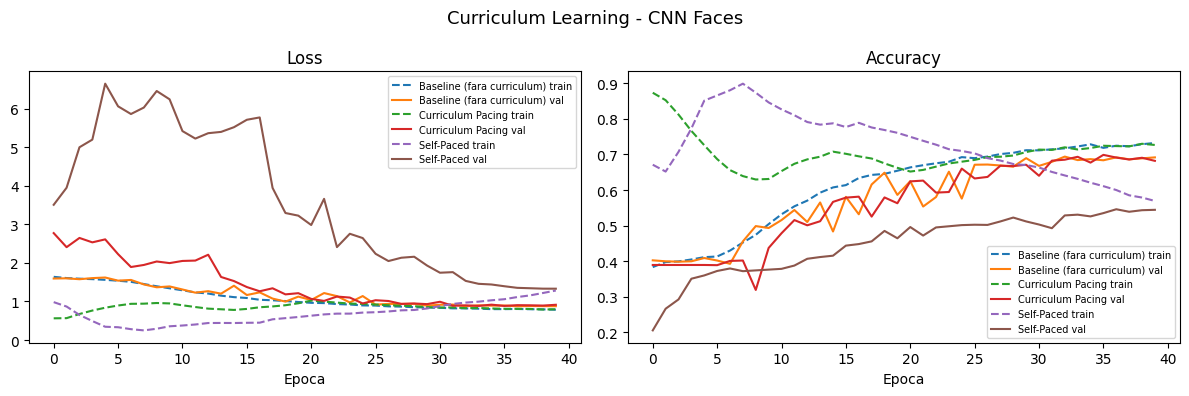


--- Metrici comparative ---

=== Baseline CNN Faces ===
Accuracy: 0.6941 | F1-macro: 0.4813 | F1-micro: 0.6941
Clasa         Precision   Recall       F1
  Surprise        0.772    0.788    0.779
  Fear            0.000    0.000    0.000
  Disgust         0.000    0.000    0.000
  Happiness       0.849    0.843    0.846
  Sadness         0.525    0.714    0.605
  Anger           0.399    0.600    0.479
  Neutral         0.671    0.648    0.659


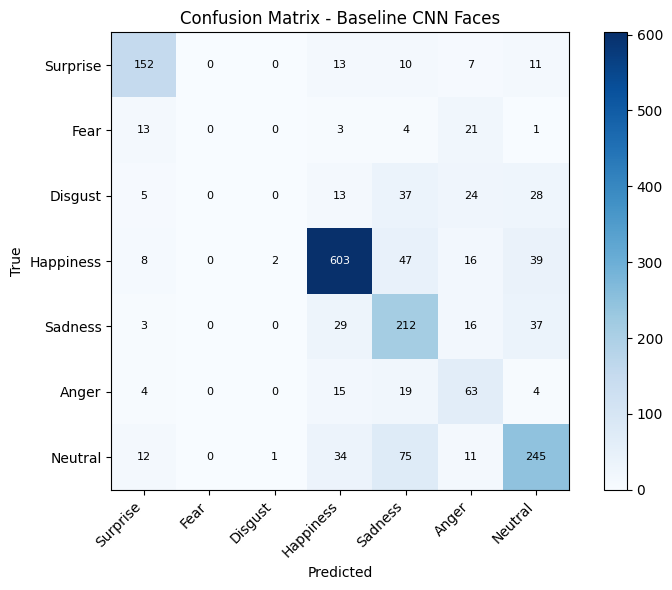


=== Curriculum Pacing Faces ===
Accuracy: 0.6990 | F1-macro: 0.5198 | F1-micro: 0.6990
Clasa         Precision   Recall       F1
  Surprise        0.774    0.782    0.778
  Fear            0.750    0.071    0.130
  Disgust         0.500    0.084    0.144
  Happiness       0.885    0.827    0.855
  Sadness         0.539    0.680    0.601
  Anger           0.362    0.600    0.452
  Neutral         0.658    0.701    0.679


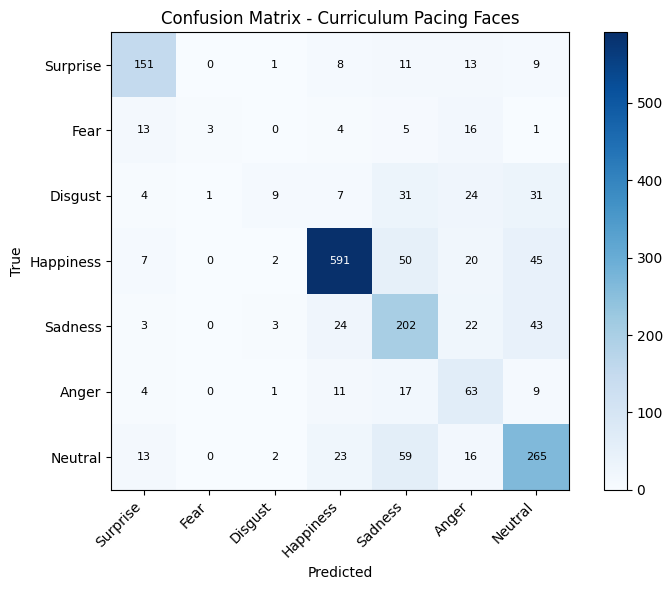


=== Self-Paced Faces ===
Accuracy: 0.5460 | F1-macro: 0.2723 | F1-micro: 0.5460
Clasa         Precision   Recall       F1
  Surprise        0.000    0.000    0.000
  Fear            0.000    0.000    0.000
  Disgust         0.000    0.000    0.000
  Happiness       0.744    0.827    0.783
  Sadness         0.311    0.327    0.319
  Anger           0.450    0.171    0.248
  Neutral         0.430    0.786    0.556


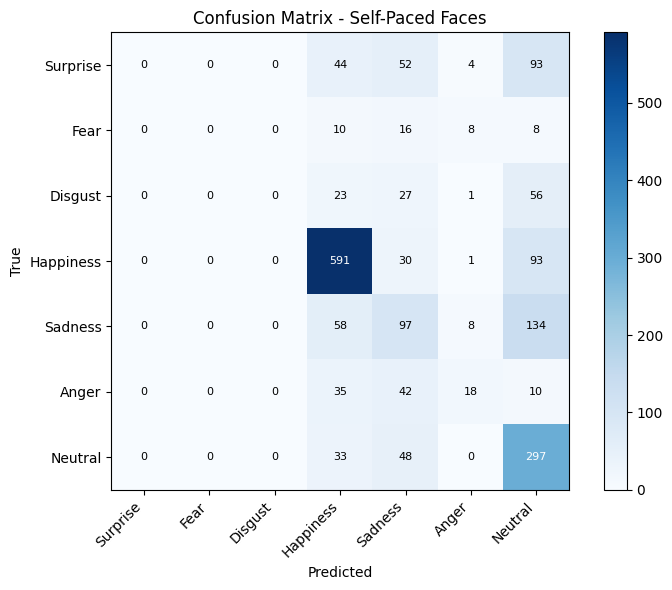

Modele curriculum salvate.


In [46]:
# Baseline: CNN antrenat normal (fara curriculum) - hist_cnn_face_bn din sectiunea 3.3
plot_history(
    [hist_cnn_face_bn, hist_cl1, hist_cl2],
    ['Baseline (fara curriculum)', 'Curriculum Pacing', 'Self-Paced'],
    title='Curriculum Learning - CNN Faces',
    save_path=f'{BASE}/bonus_curriculum_faces.png'
)

print('\n--- Metrici comparative ---')
report_metrics(cnn_face_bn,  face_val_loader, crit_cl, FACE_CLASSES, device, 'Baseline CNN Faces')
report_metrics(model_cl1, face_val_loader, crit_cl, FACE_CLASSES, device, 'Curriculum Pacing Faces')
report_metrics(model_cl2, face_val_loader, crit_cl, FACE_CLASSES, device, 'Self-Paced Faces')

torch.save(model_cl1.state_dict(), f'{BASE}/best_curriculum_pacing_faces.pt')
torch.save(model_cl2.state_dict(), f'{BASE}/best_selfpaced_faces.pt')
print('Modele curriculum salvate.')